In [1]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from pydynpd import regression


ModuleNotFoundError: No module named 'plotly'

# Data Cleaning

In [ ]:
DF = pd.read_excel("WDI_DATA.xlsx")
DF.head(7)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Afghanistan,AFG,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
1,Afghanistan,AFG,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
3,Afghanistan,AFG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,8.122551,8.389595,8.662664,8.942709,9.231134,9.529343,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
4,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,563.872337,562.769574,553.125152,557.861533,527.834554,408.625855,377.665627,378.066303,374.376696,NaN
5,Afghanistan,AFG,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.300121,-0.195570,-1.713743,0.856295,-5.382515,-22.584482,-7.576669,0.106093,-0.975915,NaN
6,Albania,ALB,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN


### GDP

In [ ]:
GDP_PPP = DF.loc[
    DF["Series Code"] ==  "NY.GDP.PCAP.PP.KD"	
]

GDP_PPP.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
8,Albania,ALB,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,14643.428561,15359.397458,16170.923433,16761.123018,16457.718974,18212.794718,19388.792728,20501.647073,21640.983577,22724.293819
14,Angola,AGO,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820
20,Algeria,DZA,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,15511.685877,15427.664189,15343.426122,15199.198997,14194.155748,14496.865470,14782.200297,15159.324237,15501.919700,15882.713884
26,Argentina,ARG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,27802.105720,28334.904185,27367.115094,26629.552942,23877.093140,26300.274261,27825.027349,27230.396850,26771.965765,27846.598460
32,Armenia,ARM,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,13192.994073,14243.874900,15037.045242,16215.360797,15052.935979,15921.705282,17886.178388,19402.751092,20078.784898,21153.478329
38,Bangladesh,BGD,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,5682.535535,6005.707188,6392.593340,6838.326116,7015.197928,7441.069140,7888.163891,8242.397990,8486.784957,8676.755762
44,Azerbaijan,AZE,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,19822.410594,19659.004856,19781.850906,20101.491875,19126.096851,20111.375695,21051.244229,21310.738692,22090.529803,22314.216896
50,Belarus,BLR,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,24846.830153,25503.980985,26363.462978,26798.820640,26731.495387,27611.180114,26537.508308,27782.438014,29135.946514,29666.211572
56,Belize,BLZ,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,12063.060037,11572.300793,11451.897941,11765.974866,10045.140416,11716.326782,12565.364583,12371.008655,12621.408196,12788.842371


In [ ]:
Full_GDP = GDP_PPP.set_index("Country Name").iloc[:,3:]
Full_GDP


,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,14643.428561,15359.397458,16170.923433,16761.123018,16457.718974,18212.794718,19388.792728,20501.647073,21640.983577,22724.293819
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,15511.685877,15427.664189,15343.426122,15199.198997,14194.155748,14496.865470,14782.200297,15159.324237,15501.919700,15882.713884
Argentina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,27802.105720,28334.904185,27367.115094,26629.552942,23877.093140,26300.274261,27825.027349,27230.396850,26771.965765,27846.598460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,9743.188223,10290.548714,10936.893786,11628.613915,11851.396569,12048.901994,12979.763898,13534.799784,14396.421737,15457.349940
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5070.424132,5234.406538,5415.493220,4993.865469,4527.739492,4827.109602,5036.783177,5218.045266,5211.897556,5529.233100


In [ ]:
GDP = GDP_PPP.set_index("Country Name").iloc[:,33:]
GDP


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
Albania,5560.833935,4027.888807,3761.139808,4145.902505,4517.780079,5151.375962,5563.770078,4942.983500,5387.545887,6085.983397,...,14643.428561,15359.397458,16170.923433,16761.123018,16457.718974,18212.794718,19388.792728,20501.647073,21640.983577,22724.293819
Angola,8366.412716,8170.249394,7445.438367,5481.763868,5377.990350,5981.532576,6565.864794,6808.336281,6893.122653,6815.175306,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820
Algeria,11728.545729,11314.864735,11241.415417,10743.706353,10414.034824,10588.443370,10808.878867,10725.967349,11094.887537,11292.037300,...,15511.685877,15427.664189,15343.426122,15199.198997,14194.155748,14496.865470,14782.200297,15159.324237,15501.919700,15882.713884
Argentina,17007.284432,18295.609200,19476.284061,20791.345148,21711.842788,20819.499948,21695.594952,23172.158340,23783.101719,22714.511130,...,27802.105720,28334.904185,27367.115094,26629.552942,23877.093140,26300.274261,27825.027349,27230.396850,26771.965765,27846.598460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,2467.964601,2560.843835,2726.473737,2890.424317,3089.609337,3328.214860,3584.028983,3820.302495,3982.958060,4119.053672,...,9743.188223,10290.548714,10936.893786,11628.613915,11851.396569,12048.901994,12979.763898,13534.799784,14396.421737,15457.349940
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,6082.868798,6254.301825,5532.061365,5509.106975,6010.768452,5964.615215,6474.188225,6524.090916,6582.376930,6423.736692,...,5070.424132,5234.406538,5415.493220,4993.865469,4527.739492,4827.109602,5036.783177,5218.045266,5211.897556,5529.233100


In [ ]:
logGDP = np.log(GDP)
logGDP

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7.992534,7.990577,7.973291,7.981817,7.926489,7.670506,7.591715,7.592776,7.582969,NaN
Albania,8.623503,8.300998,8.232477,8.329876,8.415776,8.547019,8.624031,8.505724,8.591845,8.713744,...,9.591747,9.639483,9.690970,9.726817,9.708550,9.809880,9.872450,9.928261,9.982344,10.031190
Angola,9.031980,9.008255,8.915357,8.609182,8.590070,8.696432,8.789640,8.825903,8.838279,8.826907,...,9.302372,9.265318,9.225706,9.181218,9.094362,9.073396,9.076923,9.059231,9.077129,9.077973
Algeria,9.369781,9.333873,9.327360,9.282075,9.250910,9.267518,9.288123,9.280423,9.314240,9.331853,...,9.649349,9.643918,9.638442,9.628998,9.560586,9.581688,9.601179,9.626371,9.648719,9.672987
Argentina,9.741397,9.814416,9.876953,9.942292,9.985613,9.943645,9.984865,10.050707,10.076731,10.030759,...,10.232867,10.251850,10.217097,10.189777,10.080675,10.177335,10.233691,10.212089,10.195111,10.234466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,7.811149,7.848092,7.910764,7.969159,8.035800,8.110191,8.184243,8.248085,8.289780,8.323379,...,9.184324,9.238981,9.299897,9.361224,9.380201,9.396729,9.471147,9.513019,9.574735,9.645840
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,8.713232,8.741025,8.618316,8.614158,8.701308,8.693600,8.775579,8.783257,8.792151,8.767755,...,8.531180,8.563009,8.597019,8.515966,8.417978,8.482003,8.524523,8.559878,8.558699,8.617804


### Secondary School Enrollment

In [ ]:
Sch_Edu_raw = DF.loc[
    DF["Series Code"] ==  "SE.SEC.ENRR"	
]

Sch_Edu_raw.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Afghanistan,AFG,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
6,Albania,ALB,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
12,Angola,AGO,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
18,Algeria,DZA,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
24,Argentina,ARG,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
30,Armenia,ARM,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,83.024941,86.826063,88.508030,91.485374,91.710661,89.411103,90.945871,NaN
36,Bangladesh,BGD,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,64.166455,62.340864,65.271489,65.118541,66.432955,66.828232,67.038459,65.985660,64.299719,NaN
42,Azerbaijan,AZE,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,86.585694,89.262516,108.488781,107.863961,91.365514,91.410637,90.953036,92.740297,91.122804,NaN
48,Belarus,BLR,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,102.969006,102.480850,101.596011,100.438744,100.575710,100.420639,99.060203,97.426600,94.790270,NaN
54,Belize,BLZ,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,87.731373,86.323893,86.283356,87.452660,86.188660,88.821555,87.438167,83.619554,86.457158,NaN


In [ ]:
Sch_Edu_Full = Sch_Edu_raw.set_index("Country Name").iloc[:,3:]
Sch_Edu_Full

,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
Argentina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,90.158335,91.072520,92.837771,94.654622,93.192139,92.769021,93.412343,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,43.690689,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
Sch_Edu= Sch_Edu_raw.set_index("Country Name").iloc[:,33:]
Sch_Edu

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,11.039550,17.183611,NaN,17.416910,23.468580,23.054520,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
Albania,90.841187,93.707687,80.463737,72.516083,70.497673,70.054268,68.990097,69.059052,70.327858,70.401100,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
Angola,9.642070,10.173200,11.441050,NaN,NaN,NaN,NaN,NaN,11.897480,11.770890,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
Algeria,60.615879,59.820271,60.101250,59.965199,60.480068,59.507660,58.931290,58.742439,NaN,64.745598,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
Argentina,72.955566,74.131264,NaN,NaN,70.867752,NaN,78.492607,74.477280,80.652031,92.290466,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,35.117908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.883980,NaN,...,90.158335,91.072520,92.837771,94.654622,93.192139,92.769021,93.412343,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.079121,...,43.690689,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,45.169281,46.478859,41.213879,38.712090,38.884071,40.178322,40.533009,41.581909,NaN,40.162830,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Urban Population

In [ ]:
Urb_ppln_raw = DF.loc[
    DF["Series Code"] ==  "SP.URB.TOTL.IN.ZS"	
]
Urb_ppln_raw.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
3,Afghanistan,AFG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,8.122551,8.389595,8.662664,8.942709,9.231134,9.529343,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
9,Albania,ALB,Urban population (% of total population),SP.URB.TOTL.IN.ZS,30.842067,30.982751,31.073190,31.139806,31.190633,31.233706,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
15,Angola,AGO,Urban population (% of total population),SP.URB.TOTL.IN.ZS,10.387104,10.810545,11.207060,11.581720,11.945180,12.308095,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
21,Algeria,DZA,Urban population (% of total population),SP.URB.TOTL.IN.ZS,31.341294,32.882971,34.511760,36.055670,37.378389,38.343607,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
27,Argentina,ARG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,71.723889,72.435474,73.172879,73.927374,74.687963,75.443651,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
33,Armenia,ARM,Urban population (% of total population),SP.URB.TOTL.IN.ZS,51.151337,52.481979,53.579094,54.617699,55.554516,56.057514,...,64.592875,64.712495,64.850283,65.004703,65.174217,65.357288,65.562446,65.695688,65.811367,65.928702
39,Bangladesh,BGD,Urban population (% of total population),SP.URB.TOTL.IN.ZS,5.112178,5.277111,5.465581,5.656050,5.854935,6.065048,...,29.875392,30.201580,30.517566,30.822840,31.116893,31.399216,31.673735,32.157847,32.678320,33.239585
45,Azerbaijan,AZE,Urban population (% of total population),SP.URB.TOTL.IN.ZS,48.096024,48.994537,49.009277,49.519924,49.528496,49.646301,...,55.757480,56.433189,57.184153,58.130819,58.293469,58.365997,58.438282,58.507535,58.573796,58.637102
51,Belarus,BLR,Urban population (% of total population),SP.URB.TOTL.IN.ZS,32.663029,33.895443,34.934948,35.947548,36.981735,38.023422,...,76.845871,77.020821,77.213272,77.455077,77.789039,78.131087,78.473279,78.814642,79.155102,79.494582
57,Belize,BLZ,Urban population (% of total population),SP.URB.TOTL.IN.ZS,53.885101,53.899827,53.931586,53.975710,54.027734,54.083192,...,43.676551,43.421109,43.164848,42.907762,42.649842,42.391081,42.137325,41.945944,41.753211,41.562144


In [ ]:
Urb_ppln_Full = Urb_ppln_raw.set_index("Country Name").iloc[:,3:]
Urb_ppln_Full

,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,8.122551,8.389595,8.662664,8.942709,9.231134,9.529343,9.838740,10.160728,10.496712,10.848095,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
Albania,30.842067,30.982751,31.073190,31.139806,31.190633,31.233706,31.277061,31.328732,31.396753,31.490165,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
Angola,10.387104,10.810545,11.207060,11.581720,11.945180,12.308095,12.681118,13.074905,13.500110,13.967388,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
Algeria,31.341294,32.882971,34.511760,36.055670,37.378389,38.343607,38.838323,39.101684,39.311664,39.474071,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
Argentina,71.723889,72.435474,73.172879,73.927374,74.687963,75.443651,76.183442,76.896339,77.571347,78.197471,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,15.265452,15.722280,16.117120,16.506481,16.945107,17.536407,18.353159,19.287720,20.114211,20.626317,...,32.847619,33.362596,33.941023,34.623913,35.570668,36.654066,37.547852,38.129890,38.490070,38.829916
"Yemen, Rep.",3.400000,3.594849,3.799199,4.015082,4.244533,4.489583,4.752267,5.034617,5.338667,5.666450,...,32.951201,33.558691,34.210605,34.906756,35.702560,36.070495,36.322631,36.570798,36.807752,37.033666
Zimbabwe,12.467008,12.765667,13.077449,13.467384,13.964187,14.531922,15.139939,15.757591,16.354229,16.901508,...,34.079946,34.701495,35.408554,36.183764,37.009767,37.869206,38.705521,39.291937,39.893372,40.495129


In [ ]:
Urb_ppln= Urb_ppln_Full.iloc[:,30:]
Urb_ppln

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,17.264035,17.376660,17.488203,17.600467,17.715260,17.834385,17.959649,18.092857,18.235814,18.390327,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
Albania,35.897048,36.282412,36.718428,37.201625,37.728534,38.295684,38.899604,39.536825,40.203875,40.897284,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
Angola,37.878002,39.216271,40.520577,41.784095,43.000000,44.211003,45.455601,46.720650,47.993007,49.259527,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
Algeria,52.142128,52.927181,53.705230,54.477852,55.246622,56.013117,56.778914,57.545589,58.314700,59.084465,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
Argentina,86.919733,87.215028,87.481587,87.730771,87.964583,88.185368,88.395473,88.597245,88.793031,88.985176,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,19.173504,19.439680,19.825251,20.305768,20.856783,21.453846,22.072511,22.688328,23.276849,23.821228,...,32.847619,33.362596,33.941023,34.623913,35.570668,36.654066,37.547852,38.129890,38.490070,38.829916
"Yemen, Rep.",20.182053,20.982249,21.756953,22.492356,23.170080,23.798486,24.398954,24.980873,25.543258,26.085123,...,32.951201,33.558691,34.210605,34.906756,35.702560,36.070495,36.322631,36.570798,36.807752,37.033666
Zimbabwe,29.592041,30.155585,30.567425,30.875317,31.161894,31.429986,31.676908,31.899972,32.096492,32.263783,...,34.079946,34.701495,35.408554,36.183764,37.009767,37.869206,38.705521,39.291937,39.893372,40.495129


### Government Expenditure on Education

In [ ]:
Gov_Exp_raw = DF.loc[
    DF["Series Code"] ==  "SE.XPD.TOTL.GD.ZS"	
]

Gov_Exp_raw.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
1,Afghanistan,AFG,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Albania,ALB,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
13,Angola,AGO,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
19,Algeria,DZA,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.977720,NaN
25,Argentina,ARG,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
31,Armenia,ARM,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.758120,2.707590,2.113312,2.159842,2.705560,2.767850,2.491900,2.438700,NaN,NaN
37,Bangladesh,BGD,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,1.281840,2.113429,2.094775,1.130950,2.139744,2.170909,2.085387,2.162138,2.034385,NaN
43,Azerbaijan,AZE,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.903410,2.473820,2.455430,3.176460,4.332050,3.702080,3.046890,3.660360,NaN,NaN
49,Belarus,BLR,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.946550,4.795000,4.836570,4.979490,4.862640,4.606410,4.628230,4.909030,5.045940,NaN
55,Belize,BLZ,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,5.726040,5.950720,6.127800,5.963780,5.213020,5.962990,4.604160,4.231430,4.622763,NaN


In [ ]:
Gov_Exp_Full = Gov_Exp_raw.set_index("Country Name").iloc[:,3:]
Gov_Exp_Full


,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.97772,NaN
Argentina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.469070,3.418657,3.295370,3.084998,3.216529,2.945175,2.887387,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.384771,NaN,NaN


In [ ]:
Gov_Exp = Gov_Exp_Full.iloc[:,30:]
Gov_Exp

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,NaN,NaN,NaN,NaN,3.44698,3.14191,3.05030,3.32768,3.46300,3.51435,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.56712,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.97772,NaN
Argentina,1.06738,NaN,NaN,NaN,NaN,NaN,3.73198,NaN,4.03987,4.52168,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.469070,3.418657,3.295370,3.084998,3.216529,2.945175,2.887387,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.384771,NaN,NaN


### Final Variables

In [ ]:
display(logGDP)
display(Sch_Edu)
display(Urb_ppln)
display(Gov_Exp)

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7.992534,7.990577,7.973291,7.981817,7.926489,7.670506,7.591715,7.592776,7.582969,NaN
Albania,8.623503,8.300998,8.232477,8.329876,8.415776,8.547019,8.624031,8.505724,8.591845,8.713744,...,9.591747,9.639483,9.690970,9.726817,9.708550,9.809880,9.872450,9.928261,9.982344,10.031190
Angola,9.031980,9.008255,8.915357,8.609182,8.590070,8.696432,8.789640,8.825903,8.838279,8.826907,...,9.302372,9.265318,9.225706,9.181218,9.094362,9.073396,9.076923,9.059231,9.077129,9.077973
Algeria,9.369781,9.333873,9.327360,9.282075,9.250910,9.267518,9.288123,9.280423,9.314240,9.331853,...,9.649349,9.643918,9.638442,9.628998,9.560586,9.581688,9.601179,9.626371,9.648719,9.672987
Argentina,9.741397,9.814416,9.876953,9.942292,9.985613,9.943645,9.984865,10.050707,10.076731,10.030759,...,10.232867,10.251850,10.217097,10.189777,10.080675,10.177335,10.233691,10.212089,10.195111,10.234466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,7.811149,7.848092,7.910764,7.969159,8.035800,8.110191,8.184243,8.248085,8.289780,8.323379,...,9.184324,9.238981,9.299897,9.361224,9.380201,9.396729,9.471147,9.513019,9.574735,9.645840
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,8.713232,8.741025,8.618316,8.614158,8.701308,8.693600,8.775579,8.783257,8.792151,8.767755,...,8.531180,8.563009,8.597019,8.515966,8.417978,8.482003,8.524523,8.559878,8.558699,8.617804


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,11.039550,17.183611,NaN,17.416910,23.468580,23.054520,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
Albania,90.841187,93.707687,80.463737,72.516083,70.497673,70.054268,68.990097,69.059052,70.327858,70.401100,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
Angola,9.642070,10.173200,11.441050,NaN,NaN,NaN,NaN,NaN,11.897480,11.770890,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
Algeria,60.615879,59.820271,60.101250,59.965199,60.480068,59.507660,58.931290,58.742439,NaN,64.745598,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
Argentina,72.955566,74.131264,NaN,NaN,70.867752,NaN,78.492607,74.477280,80.652031,92.290466,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,35.117908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.883980,NaN,...,90.158335,91.072520,92.837771,94.654622,93.192139,92.769021,93.412343,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.079121,...,43.690689,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,45.169281,46.478859,41.213879,38.712090,38.884071,40.178322,40.533009,41.581909,NaN,40.162830,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,17.264035,17.376660,17.488203,17.600467,17.715260,17.834385,17.959649,18.092857,18.235814,18.390327,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
Albania,35.897048,36.282412,36.718428,37.201625,37.728534,38.295684,38.899604,39.536825,40.203875,40.897284,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
Angola,37.878002,39.216271,40.520577,41.784095,43.000000,44.211003,45.455601,46.720650,47.993007,49.259527,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
Algeria,52.142128,52.927181,53.705230,54.477852,55.246622,56.013117,56.778914,57.545589,58.314700,59.084465,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
Argentina,86.919733,87.215028,87.481587,87.730771,87.964583,88.185368,88.395473,88.597245,88.793031,88.985176,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,19.173504,19.439680,19.825251,20.305768,20.856783,21.453846,22.072511,22.688328,23.276849,23.821228,...,32.847619,33.362596,33.941023,34.623913,35.570668,36.654066,37.547852,38.129890,38.490070,38.829916
"Yemen, Rep.",20.182053,20.982249,21.756953,22.492356,23.170080,23.798486,24.398954,24.980873,25.543258,26.085123,...,32.951201,33.558691,34.210605,34.906756,35.702560,36.070495,36.322631,36.570798,36.807752,37.033666
Zimbabwe,29.592041,30.155585,30.567425,30.875317,31.161894,31.429986,31.676908,31.899972,32.096492,32.263783,...,34.079946,34.701495,35.408554,36.183764,37.009767,37.869206,38.705521,39.291937,39.893372,40.495129


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,NaN,NaN,NaN,NaN,3.44698,3.14191,3.05030,3.32768,3.46300,3.51435,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.56712,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.97772,NaN
Argentina,1.06738,NaN,NaN,NaN,NaN,NaN,3.73198,NaN,4.03987,4.52168,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.469070,3.418657,3.295370,3.084998,3.216529,2.945175,2.887387,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.384771,NaN,NaN


## Treating Missing Values

### Interpolation of One year gaps

In [ ]:

# Preserve original data
Gov_Exp_original = Gov_Exp.copy()

# Retain 1990–2025
year_cols = [
    c for c in Gov_Exp.columns
    if 1990 <= int(str(c)[:4]) <= 2025
]

Gov_Exp_clean = Gov_Exp[year_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Identify isolated missing observations
single_gap = (
    Gov_Exp_clean.isna()
    & Gov_Exp_clean.shift(axis=1).notna()
    & Gov_Exp_clean.shift(-1, axis=1).notna()
)

# Calculate linear interpolation
interpolated_values = (
    Gov_Exp_clean.shift(axis=1)
    + Gov_Exp_clean.shift(-1, axis=1)
) / 2

# Fill ONLY isolated one-year gaps
Gov_Exp_interp = Gov_Exp_clean.mask(
    single_gap,
    interpolated_values
)

# Check results
print("Original missing:", Gov_Exp_clean.isna().sum().sum())

print("Values interpolated:", single_gap.sum().sum())

print("Missing after interpolation:",
      Gov_Exp_interp.isna().sum().sum())


Original missing: 2275
Values interpolated: 120
Missing after interpolation: 2155


In [ ]:
Sch_Edu_clean = Sch_Edu[year_cols].apply(
    pd.to_numeric, errors="coerce"
)

enrolment_gap = (
    Sch_Edu_clean.isna()
    & Sch_Edu_clean.shift(axis=1).notna()
    & Sch_Edu_clean.shift(-1, axis=1).notna()
)

Sch_Edu_interp = Sch_Edu_clean.mask(
    enrolment_gap,
    (
        Sch_Edu_clean.shift(axis=1)
        + Sch_Edu_clean.shift(-1, axis=1)
    ) / 2
)

print("Original missing:", Sch_Edu_clean.isna().sum().sum())

print("Values interpolated:", enrolment_gap.sum().sum())

print("Missing after interpolation:",
      Sch_Edu_interp.isna().sum().sum())

Original missing: 1941
Values interpolated: 140
Missing after interpolation: 1801


### Countries with missing values

In [ ]:
# Use the interpolated spending series
coverage = pd.DataFrame({
    "Enrolment": Sch_Edu_interp.notna().sum(axis=1),
    "Education Spending": Gov_Exp_interp.notna().sum(axis=1),
    "GDP": logGDP.notna().sum(axis=1),
    "Urban": Urb_ppln.notna().sum(axis=1)
})

coverage["Complete Years"] = (
    Sch_Edu_interp.notna()
    & Gov_Exp_interp.notna()
    & logGDP.notna()
    & Urb_ppln.notna()
).sum(axis=1)

coverage = coverage.sort_values(
    "Complete Years", ascending=False
)

display(coverage)

,Enrolment,Education Spending,GDP,Urban,Complete Years
Country Name,,,,,
Malaysia,35,32,36,36,32
Thailand,34,33,36,36,31
"Iran, Islamic Rep.",32,32,36,36,30
Peru,35,29,36,36,29
Argentina,32,29,36,36,29
...,...,...,...,...,...
"Micronesia, Fed. Sts.",2,11,36,36,0
Montenegro,19,0,29,36,0
South Sudan,3,7,0,36,0


In [ ]:

# A year is complete only when all four variables are observed
complete = (
    Sch_Edu_interp.notna()
    & Gov_Exp_interp.notna()
    & logGDP[year_cols].notna()
    & Urb_ppln[year_cols].notna()
)

def longest_run(row):
    longest = current = 0

    for observed in row:
        if observed:
            current += 1
            longest = max(longest, current)
        else:
            current = 0

    return longest

coverage["Longest Consecutive Run"] = (
    complete.apply(longest_run, axis=1)
)

coverage = coverage.sort_values(
    ["Longest Consecutive Run", "Complete Years"],
    ascending=False
)

display(coverage)


,Enrolment,Education Spending,GDP,Urban,Complete Years,Longest Consecutive Run
Country Name,,,,,,
Malaysia,35,32,36,36,32,32
Peru,35,29,36,36,29,29
Argentina,32,29,36,36,29,28
Bangladesh,28,32,36,36,28,27
St. Lucia,32,28,36,36,27,27
...,...,...,...,...,...,...
"Micronesia, Fed. Sts.",2,11,36,36,0,0
Montenegro,19,0,29,36,0,0
South Sudan,3,7,0,36,0,0


In [ ]:

def longest_run_period(row):
    best_start = None
    best_end = None
    best_length = 0

    current_start = None
    current_length = 0

    for year, observed in row.items():
        if observed:
            if current_length == 0:
                current_start = year

            current_length += 1

            if current_length > best_length:
                best_length = current_length
                best_start = current_start
                best_end = year
        else:
            current_length = 0
            current_start = None

    return pd.Series({
        "Run Start": best_start,
        "Run End": best_end,
        "Run Length": best_length
    })

run_periods = complete.apply(
    longest_run_period, axis=1
)

coverage = coverage.join(run_periods.drop(
    columns="Run Length"
))

display(
    coverage.sort_values(
        "Longest Consecutive Run",
        ascending=False
    )
)


,Enrolment,Education Spending,GDP,Urban,Complete Years,Longest Consecutive Run,Run Start,Run End
Country Name,,,,,,,,
Malaysia,35,32,36,36,32,32,1992 [YR1992],2023 [YR2023]
Peru,35,29,36,36,29,29,1996 [YR1996],2024 [YR2024]
Argentina,32,29,36,36,29,28,1996 [YR1996],2023 [YR2023]
Bangladesh,28,32,36,36,28,27,1998 [YR1998],2024 [YR2024]
St. Lucia,32,28,36,36,27,27,1998 [YR1998],2024 [YR2024]
...,...,...,...,...,...,...,...,...
"Micronesia, Fed. Sts.",2,11,36,36,0,0,NaN,NaN
Montenegro,19,0,29,36,0,0,NaN,NaN
South Sudan,3,7,0,36,0,0,NaN,NaN


In [ ]:

# Convert year labels into integer years
complete_years = complete.copy()

complete_years.columns = [
    int(str(c)[:4]) for c in complete_years.columns
]

# Test common windows of different lengths
results = []

for window in [10, 12, 15, 18, 20, 22, 25]:

    for start in range(1990, 2026 - window + 1):

        end = start + window - 1

        period = complete_years.loc[
            :, start:end
        ]

        # Countries with complete observations
        # throughout the selected window
        countries = period.all(axis=1).sum()

        results.append({
            "Start Year": start,
            "End Year": end,
            "Window": window,
            "Countries": countries
        })

window_results = pd.DataFrame(results)

# Show the best windows for each duration
best_windows = (
    window_results
    .sort_values(
        ["Window", "Countries"],
        ascending=[True, False]
    )
    .groupby("Window")
    .head(5)
    .sort_values(
        ["Window", "Countries"],
        ascending=[False, False]
    )
)

display(best_windows)


,Start Year,End Year,Window,Countries
134,1999,2023,25,10
133,1998,2022,25,7
135,2000,2024,25,6
131,1996,2020,25,3
132,1997,2021,25,3
121,2001,2022,22,15
120,2000,2021,22,14
122,2002,2023,22,14
119,1999,2020,22,12
118,1998,2019,22,7


In [ ]:
selected_period = complete_years.loc[:, 2011:2020]

selected_countries = selected_period.index[
    selected_period.all(axis=1)
]

print("Countries retained:", len(selected_countries))
print(selected_countries.tolist())

Countries retained: 43
['Albania', 'Argentina', 'Bangladesh', 'Azerbaijan', 'Belarus', 'Belize', 'Bhutan', 'Bolivia', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Chad', 'Colombia', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Fiji', 'Ghana', 'Guatemala', 'Indonesia', 'Kazakhstan', 'Jamaica', 'India', 'Kyrgyz Republic', 'Lao PDR', 'Maldives', 'Mauritius', 'Madagascar', 'Malaysia', 'Mexico', 'Moldova', 'Nepal', 'Peru', 'Pakistan', 'Namibia', 'Rwanda', 'South Africa', 'St. Lucia', 'Sierra Leone', 'Timor-Leste', 'Turkiye', 'Ukraine', 'Thailand']


In [ ]:
# Provisional balanced sample: 2011–2020
final_years = [
    c for c in year_cols
    if 2011 <= int(str(c)[:4]) <= 2020
]

Sch_Edu_final = Sch_Edu_interp.loc[
    selected_countries, final_years
]

Gov_Exp_final = Gov_Exp_interp.loc[
    selected_countries, final_years
]

GDP_final = logGDP.loc[
    selected_countries, final_years
]

Urban_final = Urb_ppln.loc[
    selected_countries, final_years
]

In [ ]:
for name, df in {
    "Enrolment": Sch_Edu_final,
    "Government Expenditure": Gov_Exp_final,
    "GDP": GDP_final,
    "Urban Population": Urban_final
}.items():
    print(
        name,
        "| Shape:", df.shape,
        "| Missing:", df.isna().sum().sum()
    )

Enrolment | Shape: (43, 10) | Missing: 0
Government Expenditure | Shape: (43, 10) | Missing: 0
GDP | Shape: (43, 10) | Missing: 0
Urban Population | Shape: (43, 10) | Missing: 0


# Data Selection, Cleaning and Preparation

## 1. Data Source and Variable Selection

The dataset for this study was constructed using indicators obtained from the World Bank's World Development Indicators (WDI) database. The analysis focuses on low- and middle-income countries and examines whether higher government expenditure on education is associated with higher secondary school enrolment.

Four indicators were selected for the empirical analysis:

| Variable | WDI Indicator | Description |
|---|---|---|
| Secondary School Enrolment | `SE.SEC.ENRR` | Gross secondary school enrolment ratio (%) |
| Government Expenditure on Education | `SE.XPD.TOTL.GD.ZS` | Government expenditure on education as a percentage of GDP |
| GDP per Capita | `NY.GDP.PCAP.PP.KD` | GDP per capita, PPP (constant international dollars) |
| Urban Population | `SP.URB.TOTL.IN.ZS` | Urban population as a percentage of total population |

Secondary school enrolment is the dependent variable, while government expenditure on education is the principal explanatory variable. GDP per capita and urban population are included as control variables to account for differences in economic development and the degree of urbanisation across countries.

## 2. Selection of Countries

The initial geographical focus was on low- and middle-income countries. This provides a relevant setting for examining the relationship between public education expenditure and enrolment, as these countries differ considerably in their economic conditions, educational infrastructure and public-sector capacity.

The final sample consists of 43 countries. The selection was guided by the availability and continuity of data across the four indicators over the chosen period. In particular, countries with sufficiently complete observations across the required variables were retained to construct a balanced panel.

The resulting dataset contains 43 countries observed over 10 years, giving a total of 430 country-year observations.

The use of a common country sample is important because it ensures that the estimated relationships are examined over the same set of countries rather than allowing the sample composition to change across years or variables.

It should be noted that the selection was primarily driven by data coverage and the requirement to construct a balanced panel. It should not be interpreted as a random or theoretically representative selection of all low- and middle-income countries. Consequently, the findings should be interpreted in the context of the countries included in the sample.

## 3. Selection of the Time Period: 2011–2020

The study uses annual observations from 2011 to 2020. The choice of this period was guided primarily by the availability of comparable observations across the selected countries and indicators.

Several considerations informed this decision:

1. **Maximising the cross-sectional sample:** Among the time windows examined, 2011–2020 allowed the inclusion of 43 countries while maintaining complete coverage across the selected indicators. This provided a larger cross-sectional sample than alternative windows that were considered.

2. **Maintaining a balanced panel:** A common ten-year period made it possible to construct a balanced dataset, with each country contributing the same number of annual observations. This avoids changes in country composition across the sample period.

3. **Suitability for dynamic panel estimation:** A ten-year time dimension provides a reasonable period over which to examine persistence in secondary school enrolment while remaining manageable for dynamic panel GMM estimation. Since GMM relies on lagged observations as instruments, the availability of a consistent time series is important.

4. **Avoiding excessive missingness:** Extending the period beyond the selected window would have introduced additional coverage limitations for some countries and indicators. Restricting the sample to 2011–2020 helped avoid a substantially more incomplete dataset.

The period was therefore selected as a practical balance between the number of countries, the length of the time series and the availability of comparable data. It is a data-coverage decision rather than a claim that 2011 or 2020 represents a theoretically determined structural break.

## 4. Data Cleaning and Construction of the Panel

The four WDI indicators were initially retrieved separately and subsequently combined into a single country-year dataset.

The following cleaning procedure was followed:

### 4.1 Merging the Individual Datasets

The datasets for secondary school enrolment, government expenditure on education, GDP per capita and urban population were merged using country identifiers and year as the common keys.

This ensured that each observation represented a particular country in a particular year, with all four indicators aligned to the same country-year combination.

Country identifiers were retained alongside country names to ensure consistent merging and panel identification.

### 4.2 Diagnosing Missing Observations

After merging, missing observations were examined across the variables and countries. This step was necessary because WDI coverage is not uniform across countries and indicators.

Rather than applying a blanket imputation procedure, missing observations were examined in relation to their position in the time series.

The treatment of missing observations was particularly important for the two main variables: secondary school enrolment and government expenditure on education.

### 4.3 Interpolation of Isolated Missing Values

For secondary school enrolment and government expenditure on education, only isolated one-year gaps were interpolated where valid observations were available in the immediately preceding and following years.

Linear interpolation was used to estimate these isolated missing values. The procedure was restricted to gaps surrounded by observed values.

For an isolated missing observation in year \(t\), interpolation takes the form:

$$
X_t = \frac{X_{t-1}+X_{t+1}}{2}
$$

where \(X_t\) represents the missing value, and the adjacent years provide the observed values used for interpolation.

The procedure was deliberately restricted:

- Only isolated one-year gaps were interpolated.
- Consecutive missing observations were not interpolated.
- Missing observations at the beginning or end of a country's time series were not extrapolated.
- Mean imputation was not used.
- Forward filling and backward filling were not applied.

This approach was adopted to preserve as much observed information as possible without introducing extensive artificial variation into the panel.

The original datasets were retained, so the interpolated values did not replace the underlying source data.

### 4.4 Treatment of GDP per Capita

GDP per capita was obtained in constant international dollars using purchasing power parity (PPP). This measure was selected to improve comparability of real income levels across countries by accounting for differences in purchasing power.

The variable was subsequently transformed using the natural logarithm:

$$
LogGDP_{it} = \ln(GDPPC_{it})
$$

The logarithmic transformation helps account for the scale differences in GDP per capita across countries and allows the regression to capture changes in income in proportional rather than purely absolute terms.

### 4.5 Urban Population

Urban population was retained as a percentage of the total population. It was included as a control variable to account for differences in urbanisation across countries and over time.

No transformation was applied to this variable.

### 4.6 Construction of the Final Balanced Panel

Following the merging, missing-value diagnosis, restricted interpolation and variable transformations, the final sample was restricted to the selected countries and the common period of 2011–2020.

The resulting dataset contained:

| Dataset characteristic | Value |
|---|---:|
| Countries | 43 |
| Years | 10 |
| Time period | 2011–2020 |
| Observations | 430 |
| Panel structure | Balanced |
| Number of variables used in estimation | 4 |

The final dataset was checked for duplicate country-year observations and remaining missing values in the variables used for estimation.

The balanced structure implies:

$$
N \times T = 43 \times 10 = 430
$$

where \(N\) denotes the number of countries and \(T\) denotes the number of annual observations per country.

## 5. Preparation for Dynamic Panel Estimation

Since the empirical specification includes lagged secondary school enrolment, the panel was sorted by country identifier and year before generating the lagged dependent variable.

The dynamic specification is:

$$
Enrolment_{it} =
\alpha Enrolment_{i,t-1}
+\beta Expenditure_{it}
+\gamma_1 LogGDP_{it}
+\gamma_2 Urban_{it}
+\mu_i+\lambda_t+\varepsilon_{it}
$$

The introduction of the lagged dependent variable necessarily reduces the number of usable observations. Furthermore, the first-differenced specification used in Difference GMM requires additional time observations for differencing and constructing valid lagged instruments.

Consequently, although the original balanced panel contains 430 observations, the controlled GMM estimations use 344 observations across 43 countries. This reduction is associated with the dynamic structure, lag requirements and instrument construction rather than the removal of countries from the original sample.

## 6. Limitations of the Data Preparation

A few limitations should be acknowledged.

First, the final sample is conditional on the availability of WDI observations. Countries with insufficient data coverage are not represented, which may limit the generalisability of the results to all low- and middle-income economies.

Second, linear interpolation assumes that the variable changes approximately linearly between the two observed adjacent years. Actual government expenditure and enrolment may not follow such a pattern. Although interpolation was restricted to isolated gaps, the estimated observations should still be distinguished from directly reported WDI values.

Third, the ten-year period provides a relatively short time dimension for dynamic panel estimation. This is relevant because GMM estimates can be sensitive to instrument selection and finite-sample properties, particularly when the dependent variable is highly persistent.

Finally, the use of GDP per capita and urban population as controls does not account for every factor affecting secondary school enrolment. Institutional quality, education infrastructure, demographic composition and differences in education policy may also influence the relationship being examined.

## 7. Summary

The final dataset is a balanced panel of 43 low- and middle-income countries over the period 2011–2020, comprising 430 country-year observations. It was constructed by merging four WDI indicators, diagnosing missing observations, interpolating only isolated one-year gaps in secondary school enrolment and government education expenditure, and transforming GDP per capita into its natural logarithm.

The country sample and time period were selected to maximise usable cross-country coverage while maintaining a consistent balanced panel suitable for dynamic panel estimation. The resulting dataset provides a common empirical basis for estimating the relationship between government expenditure on education and secondary school enrolment using pooled OLS, Fixed Effects, Difference GMM and System GMM.

## Outliers

### Visual Test

In [ ]:
GDP_long = (
    GDP_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="GDP"
       )
)

GDP_long["Year"] = (
    GDP_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [ ]:
Sch_Edu_long = (
    Sch_Edu_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="Secondary Education"
       )
)

Sch_Edu_long["Year"] = (
    Sch_Edu_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [ ]:
Urban_long = (
    Urban_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="Urban Population"
       )
)

Urban_long["Year"] = (
    Urban_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [ ]:
Gov_Exp_long = (
    Gov_Exp_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="Gov Exp"
       )
)

Gov_Exp_long["Year"] = (
    Gov_Exp_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [ ]:

fig = px.line(
    Gov_Exp_long,
    x="Year",
    y="Gov Exp",
    color="Country Name",
    title="Government Expenditure on Education"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="Gov Exp",
    legend_title="Select Countries"
)

fig.show()

In [ ]:

fig = px.line(
    GDP_long,
    x="Year",
    y="GDP",
    color="Country Name",
    title="Log GDP Trends Across Countries"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="GDP",
    legend_title="Select Countries"
)

fig.show()

In [ ]:

fig = px.line(
    Urban_long,
    x="Year",
    y="Urban Population",
    color="Country Name",
    title="Urban Population"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="Urban Population",
    legend_title="Select Countries"
)

fig.show()

In [ ]:

fig = px.line(
    Sch_Edu_long,
    x="Year",
    y="Secondary Education",
    color="Country Name",
    title="Secondary Education"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="Secondary Education",
    legend_title="Select Countries"
)

fig.show()

### Descriptive Statistics

#### Data Prep

In [ ]:
# Convert the four final datasets into long-format series
descriptive_data = pd.DataFrame({
    "Enrolment": Sch_Edu_final.stack(),
    "Education Expenditure": Gov_Exp_final.stack(),
    "Log GDP per Capita (PPP)": GDP_final.stack(),
    "Urban Population": Urban_final.stack()
})

# Ensure numeric values
descriptive_data = descriptive_data.apply(
    pd.to_numeric, errors="coerce"
)

# Check dimensions and missing values
print("Dataset shape:", descriptive_data.shape)
print("\nMissing values:")
print(descriptive_data.isna().sum())

display(descriptive_data.head())


Dataset shape: (430, 4)

Missing values:
Enrolment                   0
Education Expenditure       0
Log GDP per Capita (PPP)    0
Urban Population            0
dtype: int64


Enrolment  Education Expenditure  \
Country Name                                                    
Albania      2011 [YR2011]   95.470528               3.178813   
             2012 [YR2012]   97.608612               3.295340   
             2013 [YR2013]  102.903210               3.533550   
             2014 [YR2014]  103.321378               3.181777   
             2015 [YR2015]  102.440729               3.413000   

                            Log GDP per Capita (PPP)  Urban Population  
Country Name                                                            
Albania      2011 [YR2011]                  9.405337         53.291738  
             2012 [YR2012]                  9.430561         53.863755  
             2013 [YR2013]                  9.462921         54.297968  
             2014 [YR2014]                  9.500507         54.732581  
             2015 [YR2015]                  9.537971         55.157929

#### Mean, Standard Deviation, and IQR

In [ ]:

# Select only the two variables of interest
comparison_data = descriptive_data[
    ["Education Expenditure", "Enrolment"]
]

# Calculate descriptive statistics
comparison_stats = comparison_data.describe().T

# Add variance and IQR
comparison_stats["Variance"] = comparison_data.var()

comparison_stats["IQR"] = (
    comparison_data.quantile(0.75)
    - comparison_data.quantile(0.25)
)

# Rename columns
comparison_stats = comparison_stats.rename(
    columns={
        "count": "N",
        "mean": "Mean",
        "std": "Std. Dev.",
        "min": "Minimum",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "max": "Maximum"
    }
)

display(comparison_stats.round(3))


,N,Mean,Std. Dev.,Minimum,Q1,Median,Q3,Maximum,Variance,IQR
Education Expenditure,430.0,4.372,1.629,0.964,3.292,4.322,5.321,10.593,2.654,2.029
Enrolment,430.0,77.886,23.310,20.002,66.223,84.443,95.860,124.331,543.340,29.637


The table above we compute the Aggregate Descriptive Statistics, and then below we move to country wise Descriptive Statistics, both are for Government Spending on Education and Secondary Education Enrolment 

In [ ]:

variables = {
    "Enrolment": Sch_Edu_final,
    "Education Expenditure": Gov_Exp_final,
    "Log GDP per Capita": GDP_final,
    "Urban Population": Urban_final
}

country_descriptive = {}

for name, df in variables.items():

    stats = df.T.describe().T

    stats["IQR"] = stats["75%"] - stats["25%"]

    country_descriptive[name] = stats[
        ["mean", "50%", "std", "min", "max", "IQR"]
    ].rename(columns={
        "mean": "Mean",
        "50%": "Median",
        "std": "Std Dev",
        "min": "Minimum",
        "max": "Maximum"
    })

# Display expenditure statistics
display(
    country_descriptive["Education Expenditure"].round(3)
)

# Display enrolment statistics
display(
    country_descriptive["Enrolment"].round(3)
)


,Mean,Median,Std Dev,Minimum,Maximum,IQR
Country Name,,,,,,
Albania,3.435,3.369,0.285,3.082,3.920,0.333
Argentina,5.314,5.354,0.297,4.772,5.776,0.170
Bangladesh,1.901,2.097,0.378,1.131,2.175,0.232
Azerbaijan,2.787,2.553,0.630,2.068,4.332,0.494
Belarus,4.868,4.850,0.103,4.685,5.009,0.156
Belize,5.559,5.496,0.366,5.125,6.128,0.646
Bhutan,5.609,5.466,0.944,4.317,6.929,1.612
Bolivia,7.630,8.053,0.735,6.451,8.437,1.160
Burkina Faso,4.583,4.366,0.800,3.603,5.628,1.393


,Mean,Median,Std Dev,Minimum,Maximum,IQR
Country Name,,,,,,
Albania,99.226,98.919,2.812,95.471,103.321,4.040
Argentina,107.416,108.552,3.763,100.885,112.377,5.286
Bangladesh,59.732,60.881,5.940,49.752,66.433,8.784
Azerbaijan,90.063,85.698,9.970,82.762,108.489,7.627
Belarus,103.564,102.932,2.822,100.439,108.990,2.453
Belize,83.124,83.741,4.139,76.127,87.731,5.878
Bhutan,82.537,85.454,7.911,66.986,90.619,8.774
Bolivia,88.757,88.845,1.592,85.300,90.615,0.710
Burkina Faso,32.953,33.913,6.252,23.176,40.077,10.639


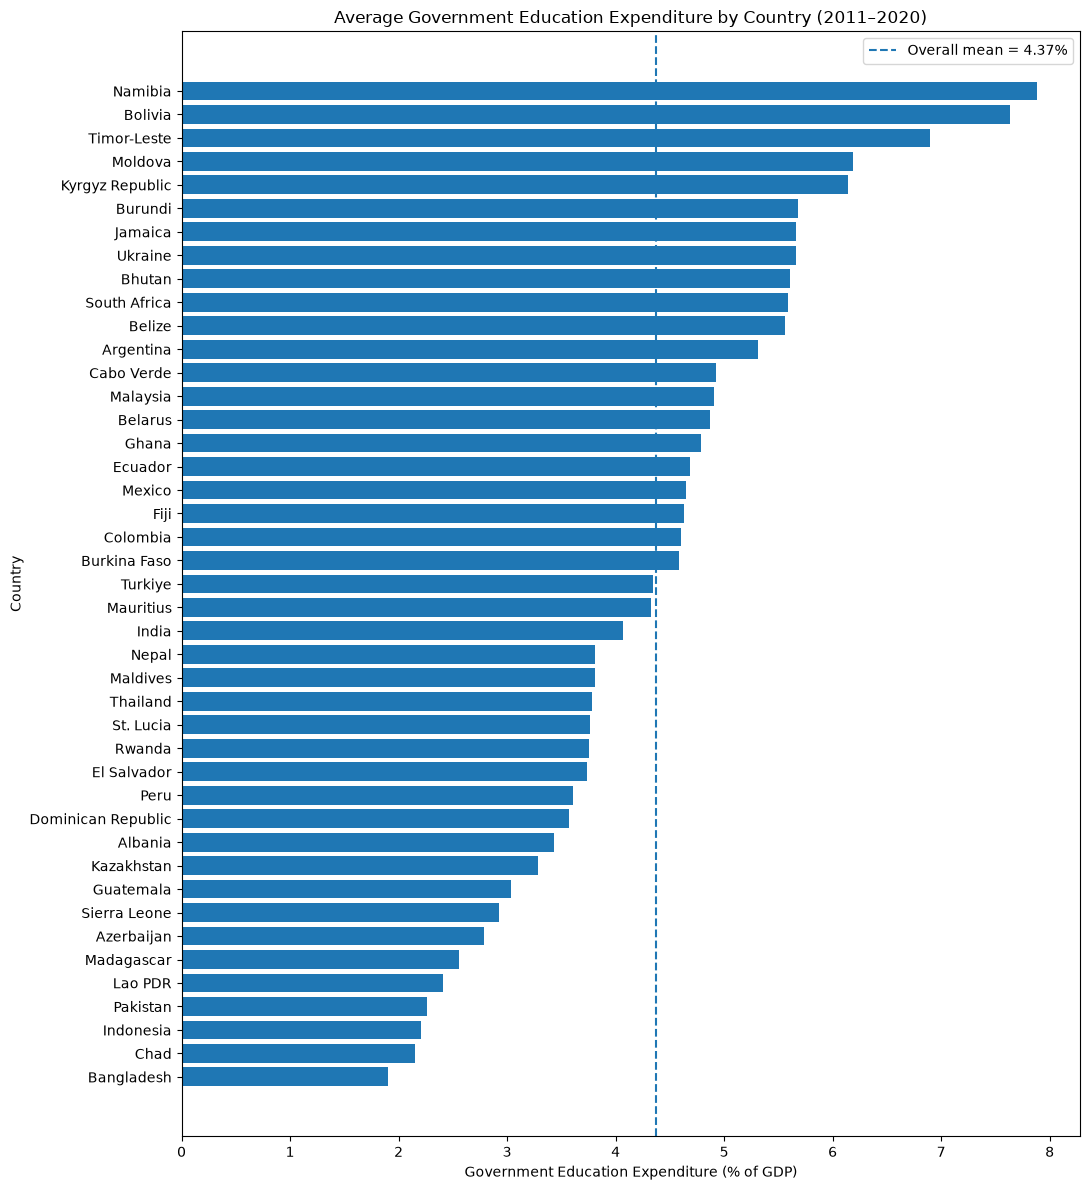

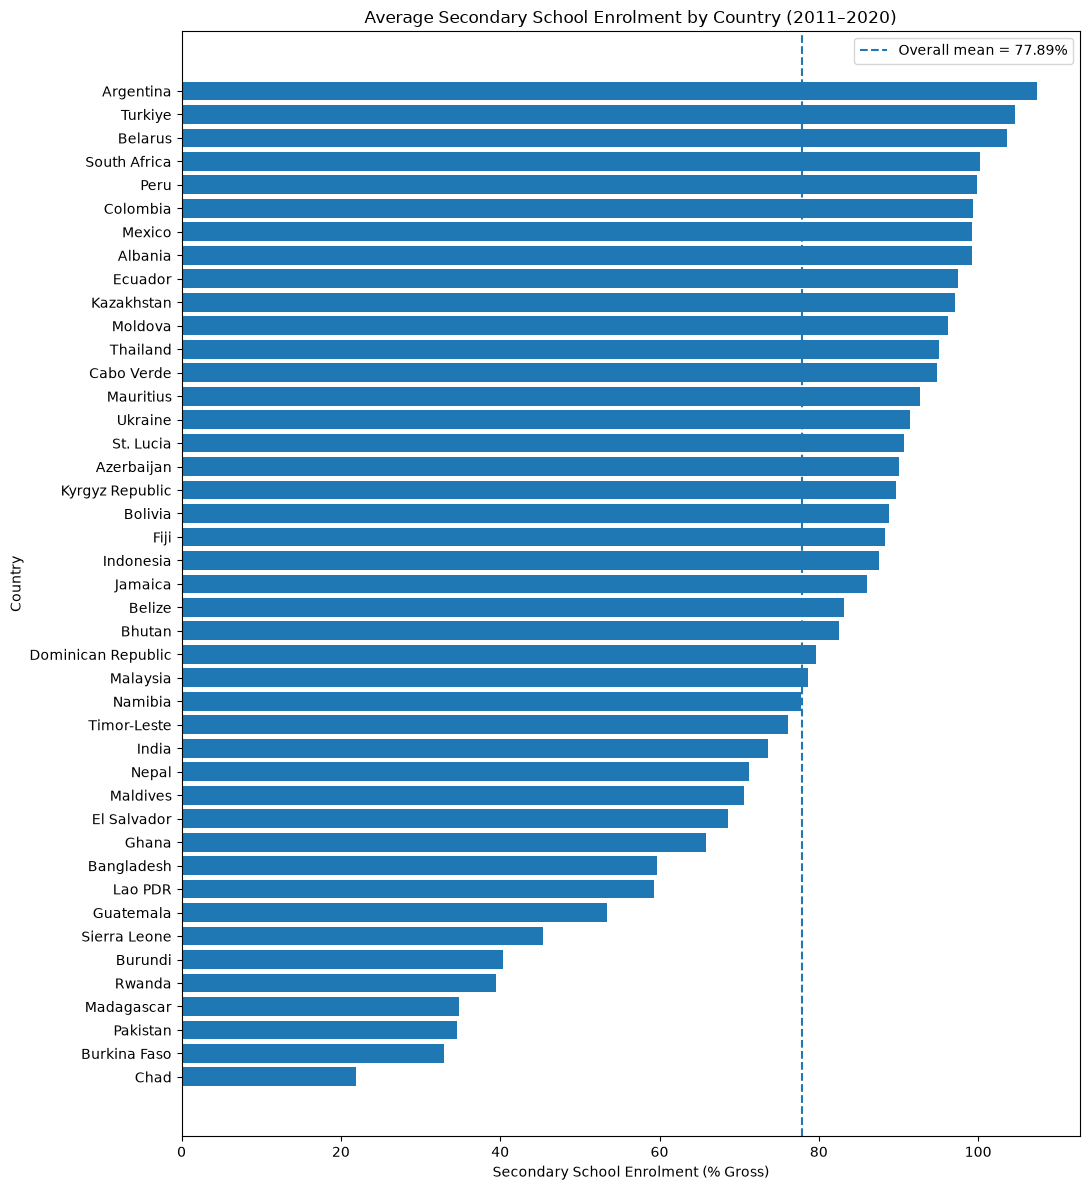

In [ ]:
expenditure = pd.read_csv("Expenditure_DS.csv")
enrolment = pd.read_csv("Enrolment_DS.csv")
aggregate = pd.read_csv("Aggregate_DS.csv")

# Overall pooled means
expenditure_mean = aggregate.iloc[0]["Mean"]
enrolment_mean = aggregate.iloc[1]["Mean"]

# Sort countries by their respective means
expenditure = expenditure.sort_values("Mean")
enrolment = enrolment.sort_values("Mean")


# Graph 1: Government education expenditure


plt.figure(figsize=(11, 12))

plt.barh(
    expenditure["Country Name"],
    expenditure["Mean"]
)

plt.axvline(
    expenditure_mean,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall mean = {expenditure_mean:.2f}%"
)

plt.xlabel("Government Education Expenditure (% of GDP)")
plt.ylabel("Country")
plt.title("Average Government Education Expenditure by Country (2011–2020)")
plt.legend()
plt.tight_layout()
plt.show()



# Graph 2: Secondary school enrolment


plt.figure(figsize=(11, 12))

plt.barh(
    enrolment["Country Name"],
    enrolment["Mean"]
)

plt.axvline(
    enrolment_mean,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall mean = {enrolment_mean:.2f}%"
)

plt.xlabel("Secondary School Enrolment (% Gross)")
plt.ylabel("Country")
plt.title("Average Secondary School Enrolment by Country (2011–2020)")
plt.legend()
plt.tight_layout()
plt.show()


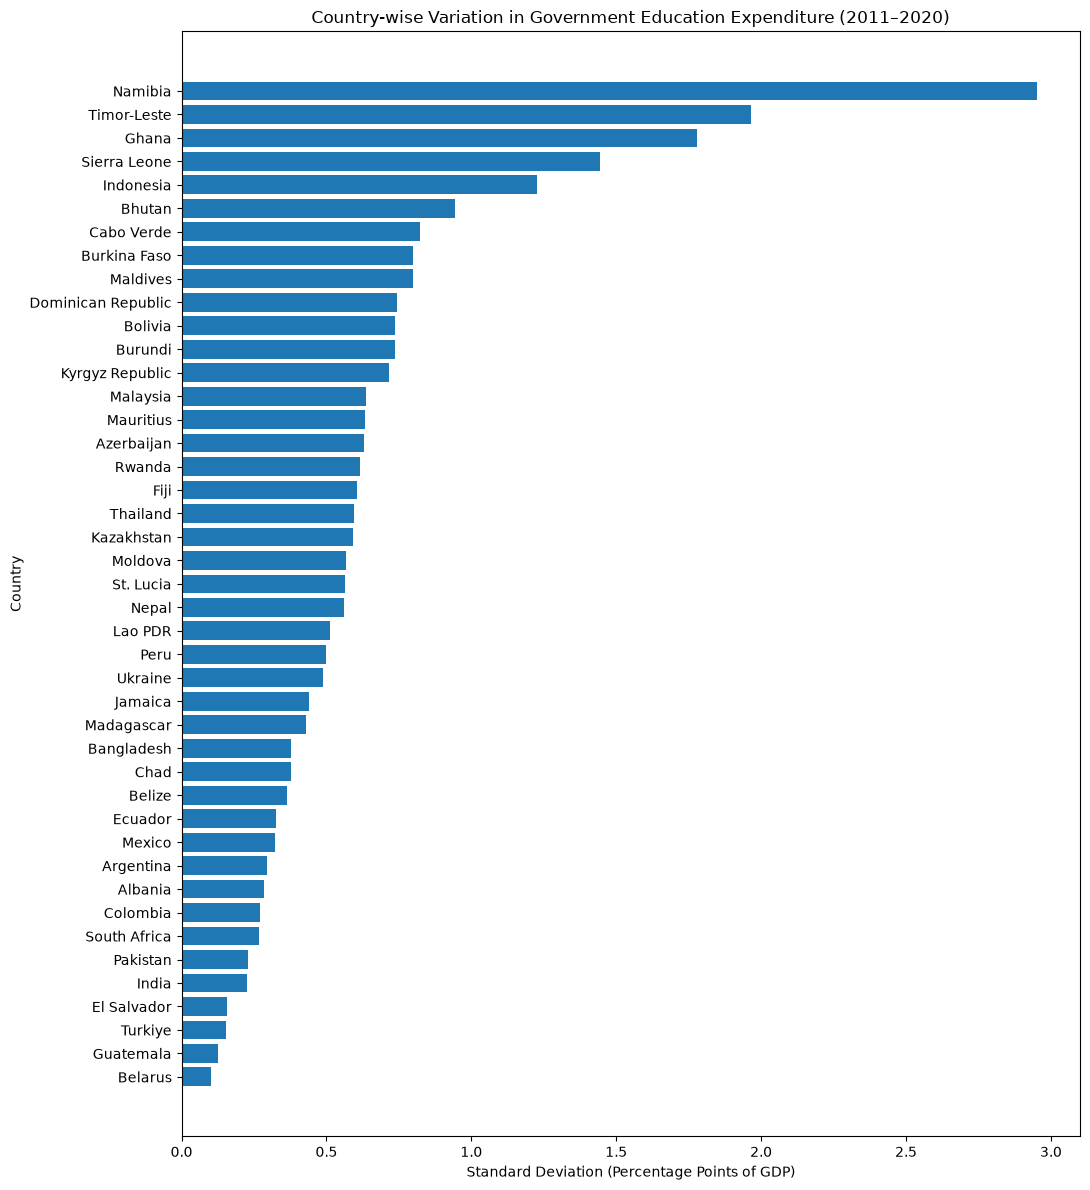

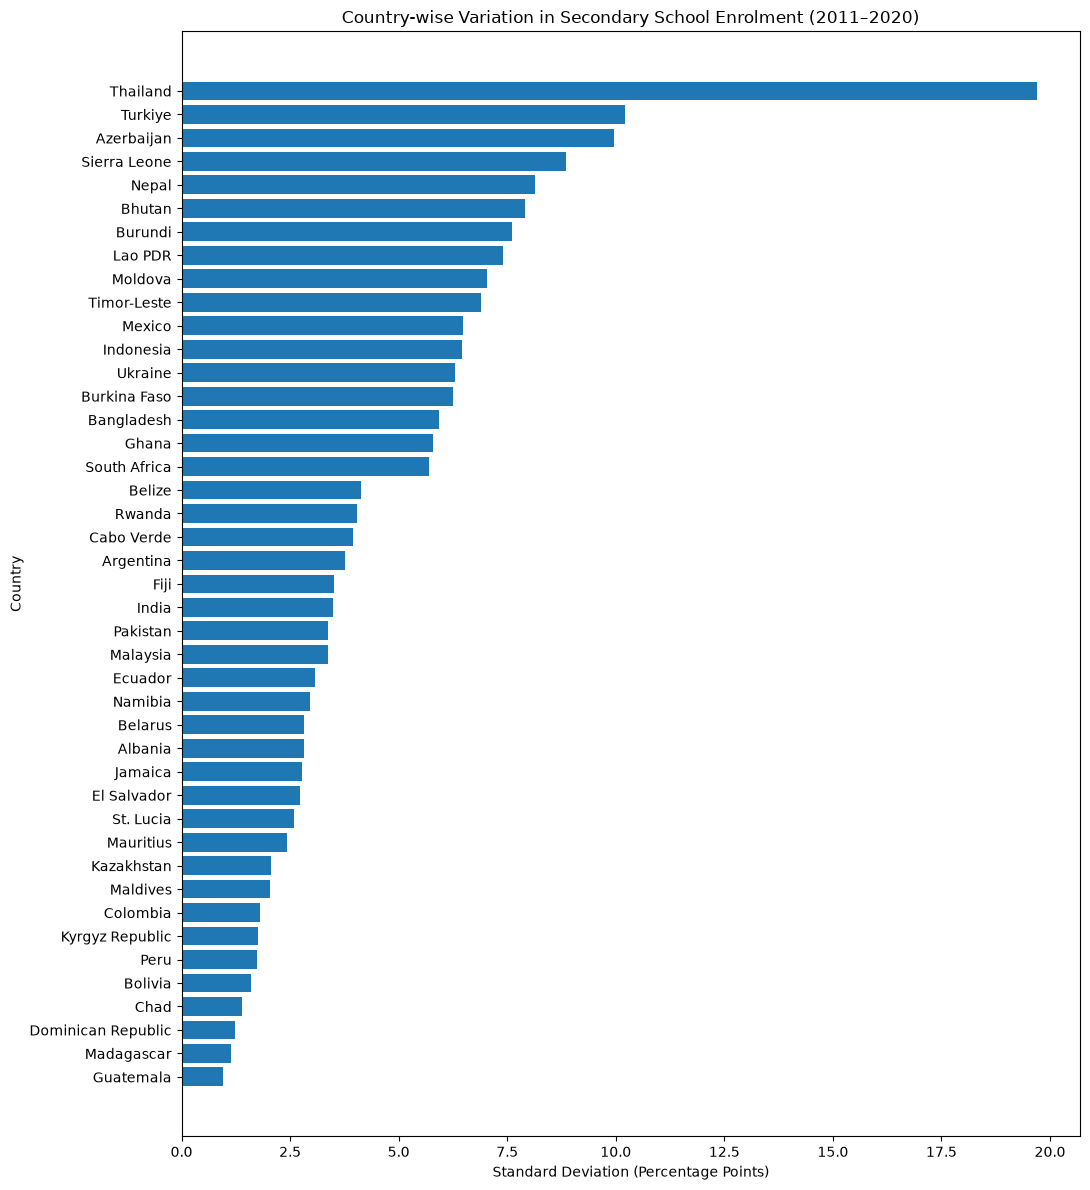

In [ ]:
# Calculate country-wise standard deviations
expenditure_sd = Gov_Exp_final.std(axis=1).sort_values()
enrolment_sd = Sch_Edu_final.std(axis=1).sort_values()


# Graph 1: Government expenditure


plt.figure(figsize=(11, 12))

plt.barh(
    expenditure_sd.index,
    expenditure_sd.values
)

plt.xlabel("Standard Deviation (Percentage Points of GDP)")
plt.ylabel("Country")
plt.title(
    "Country-wise Variation in Government Education Expenditure (2011–2020)"
)

plt.tight_layout()
plt.show()



# Graph 2: Secondary enrolment


plt.figure(figsize=(11, 12))

plt.barh(
    enrolment_sd.index,
    enrolment_sd.values
)

plt.xlabel("Standard Deviation (Percentage Points)")
plt.ylabel("Country")
plt.title(
    "Country-wise Variation in Secondary School Enrolment (2011–2020)"
)

plt.tight_layout()
plt.show()


In [ ]:
#IQR
variables = {
    "Government Education Expenditure": Gov_Exp_final,
    "Secondary School Enrolment": Sch_Edu_final
}

for name, df in variables.items():

    print(f"\n{name}")

    Q1 = df.quantile(0.25, axis=1)
    Q3 = df.quantile(0.75, axis=1)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        df.lt(lower, axis=0)
        | df.gt(upper, axis=0)
    )

    print("Total flagged observations:", outliers.sum().sum())

    # Display flagged country-year observations
    flagged = df.where(outliers).stack()

    display(flagged.rename("Flagged Value").to_frame())



Government Education Expenditure
Total flagged observations: 26


Flagged Value
Country Name                                   
Argentina          2015 [YR2015]       5.776110
                   2018 [YR2018]       4.877740
                   2019 [YR2019]       4.771660
Bangladesh         2016 [YR2016]       1.281840
                   2019 [YR2019]       1.130950
Azerbaijan         2020 [YR2020]       4.332050
Cabo Verde         2012 [YR2012]       5.397696
                   2019 [YR2019]       4.165290
                   2020 [YR2020]       7.094007
Colombia           2013 [YR2013]       4.878550
                   2020 [YR2020]       5.261660
Dominican Republic 2011 [YR2011]       1.879258
                   2012 [YR2012]       2.753720
                   2020 [YR2020]       4.517699
El Salvador        2019 [YR2019]       3.387110
Fiji               2020 [YR2020]       5.805195
Ghana              2011 [YR2011]       8.140970
                   2012 [YR2012]       7.919140
Maldives           2020 [YR2020]       5.847608
Namibia            2014 [YR2014]       3.667112
                   2017 [YR2017]       1.395245
South Africa       2019 [YR2019]       5.911590
                   2020 [YR2020]       6.170670
St. Lucia          2016 [YR2016]       5.209550
Turkiye            2016 [YR2016]       4.627740
                   2020 [YR2020]       4.033820


Secondary School Enrolment
Total flagged observations: 23


Flagged Value
Country Name                                   
Azerbaijan         2018 [YR2018]     108.488781
                   2019 [YR2019]     107.863961
Belarus            2011 [YR2011]     108.989867
Bolivia            2011 [YR2011]      85.300408
                   2012 [YR2012]      87.010851
                   2015 [YR2015]      90.613903
                   2016 [YR2016]      90.615285
Cabo Verde         2011 [YR2011]      86.700015
Dominican Republic 2011 [YR2011]      77.427220
                   2012 [YR2012]      77.986106
                   2019 [YR2019]      81.856236
Ghana              2011 [YR2011]      55.606930
                   2012 [YR2012]      56.732602
                   2020 [YR2020]      74.010219
Kazakhstan         2020 [YR2020]      91.949021
Peru               2011 [YR2011]      97.523148
                   2012 [YR2012]      96.438110
Rwanda             2013 [YR2013]      30.209286
St. Lucia          2011 [YR2011]      96.602089
Sierra Leone       2019 [YR2019]      61.198078
                   2020 [YR2020]      62.560680
Turkiye            2011 [YR2011]      87.803223
                   2012 [YR2012]      85.020432

## Descriptive Statistics and Outlier Assessment

The descriptive analysis examines the distribution of government education expenditure and secondary school enrolment across 43 countries over the period 2011–2020. The final balanced panel consists of 430 country-year observations for each variable. The analysis focuses on three aspects: the average levels of the two variables, the extent of variation across countries and over time, and the identification of potentially unusual observations using the Interquartile Range (IQR) method.

### 1. Mean and Cross-Country Differences

The pooled descriptive statistics indicate considerable variation in both government education expenditure and secondary school enrolment across the sample. Government education expenditure, measured as a percentage of GDP, has a pooled mean of approximately 4.37%. The country-wise averages range from approximately 1.90% in Bangladesh to 7.89% in Namibia. This suggests substantial differences in the proportion of national economic output allocated to education across the countries considered. While some countries allocate a relatively high share of GDP to education, others devote a considerably smaller share.

Secondary school enrolment, measured using the gross enrolment ratio, has a pooled mean of approximately 77.89%. The country-wise averages range from approximately 21.95% in Chad to 107.42% in Argentina. The relatively wide range indicates considerable cross-country differences in secondary education participation. It is important to note that the gross enrolment ratio can exceed 100%, as its numerator includes all students enrolled at the secondary level, irrespective of whether they belong to the official age group for that level of education. Therefore, values above 100% do not necessarily indicate an error in the data.

The country-wise mean comparisons provide an initial indication of the differences in education financing and enrolment across the sample. However, the two indicators do not necessarily move together in a uniform manner. For instance, Namibia and Bolivia record relatively high average government education expenditure, but their average enrolment levels are not among the highest in the sample. Conversely, countries such as Argentina and Türkiye exhibit high average enrolment alongside relatively high education expenditure. These differences suggest that expenditure alone may not fully explain cross-country variation in enrolment. Other factors, including household characteristics, demographic composition, economic conditions, institutional capacity and the efficiency with which public resources are utilised, may also be relevant. These observations are descriptive and do not establish any causal relationship between the two variables.

### 2. Country-Wise Variation and Standard Deviation

While the country-wise means capture differences in the average levels of the two indicators, they do not reveal how stable these indicators have been over time. To examine this aspect, the standard deviation was calculated separately for each country over the ten-year period. A higher standard deviation indicates greater dispersion of annual observations around that country's mean, whereas a lower standard deviation indicates comparatively greater stability.

Government education expenditure displays considerable variation in its temporal stability across countries. Namibia records the highest standard deviation, followed by Timor-Leste and Ghana. Sierra Leone and Indonesia also exhibit relatively high variation in expenditure over the period. In contrast, countries such as Belarus, Guatemala and Türkiye display comparatively low standard deviations, suggesting that their government education expenditure as a share of GDP remained relatively stable over the sample period. These differences indicate that countries vary not only in the average share of GDP allocated to education, but also in the consistency of their expenditure patterns over time.

A similar exercise for secondary school enrolment reveals substantial differences in the stability of enrolment outcomes. Thailand records the highest standard deviation, followed by Türkiye and Azerbaijan. Sierra Leone, Nepal and Bhutan also display relatively high variation. At the other end of the distribution, Guatemala, Madagascar and the Dominican Republic exhibit comparatively low standard deviations, indicating relatively stable enrolment levels during the period.

The comparison of standard deviations highlights an important distinction between the two variables. Countries with relatively stable government education expenditure do not necessarily have equally stable enrolment outcomes, and vice versa. For example, Thailand exhibits comparatively high variation in secondary school enrolment despite having relatively low variation in government education expenditure. Similarly, Namibia displays the highest variation in education expenditure but relatively low variation in enrolment. This suggests that changes in public education expenditure do not necessarily translate into immediate or proportionate changes in enrolment. However, the standard deviation alone cannot establish whether expenditure fluctuations are associated with enrolment fluctuations; this relationship is examined separately in the correlation analysis.

### 3. Identification of Potentially Unusual Observations Using the IQR Method

An Interquartile Range (IQR) procedure was employed to identify potentially unusual observations in the panel. The IQR is calculated as the difference between the third quartile and the first quartile:

$$
IQR = Q_3 - Q_1
$$

Following the conventional 1.5 IQR rule, observations below the lower bound or above the upper bound are flagged:

$$
\text{Lower Bound} = Q_1 - 1.5(IQR)
$$

$$
\text{Upper Bound} = Q_3 + 1.5(IQR)
$$

The procedure was applied separately to each country, using its ten annual observations for each variable. This approach identifies observations that are unusual relative to the historical distribution of the respective variable within that country, rather than comparing all countries against a single common distribution.

The exercise flagged 26 country-year observations for government education expenditure and 23 observations for secondary school enrolment, out of 430 observations for each variable. These represent approximately 6.05% and 5.35% of the respective samples. The flagged observations were treated as potential outliers requiring diagnostic attention, rather than automatically being classified as data errors.

Since the country-wise IQR calculations are based on only ten annual observations per country, the quartile estimates may be sensitive to individual observations. Furthermore, differences in national education systems and economic conditions mean that unusually high or low values may represent genuine changes rather than measurement errors. This is particularly relevant for secondary school gross enrolment, which can legitimately exceed 100%. Consequently, the IQR procedure was used as a screening exercise and not as a basis for automatically excluding observations.

Flagged values were checked with original WDI data set to see if there was no development of inconsistency during data handling, along with few visual tests. Thereafter, No observations were removed or winsorised solely on the basis of the IQR results. All 430 observations for each variable were retained for the subsequent analysis. This preserves potentially meaningful variation in the data while avoiding arbitrary adjustments to the sample.

### 4. Summary of Descriptive Findings

Overall, the descriptive analysis reveals substantial cross-country heterogeneity in both government education expenditure and secondary school enrolment. The differences in country-wise means indicate that countries vary considerably in the share of GDP allocated to education and in the extent of secondary school participation. The standard deviation analysis further demonstrates that the temporal stability of these indicators also differs across countries. Some countries exhibit relatively stable expenditure and enrolment patterns, whereas others experience considerably greater fluctuations over the period.

The IQR exercise identified a limited number of potentially unusual country-year observations, but the results did not provide sufficient grounds for treating these observations as data errors or excluding them from the analysis. The observations were therefore retained, and the original balanced panel was preserved.

These findings establish the extent of variation present in the sample and provide a descriptive foundation for the subsequent econometric analysis. In particular, the differences in average levels and temporal variation raise the question of whether government education expenditure is systematically associated with secondary school enrolment. The next section examines this relationship through pooled and country-wise correlation analysis, as well as a comparison of country-level averages. It is important to distinguish between associations across countries and relationships within individual countries over time, since these capture different dimensions of the data.

### Correlations

First we just do a scatter graph to gain an intuitive visual of the possible correlations, there after we perform an aggregate correlation matrix and a country wise correlation graph

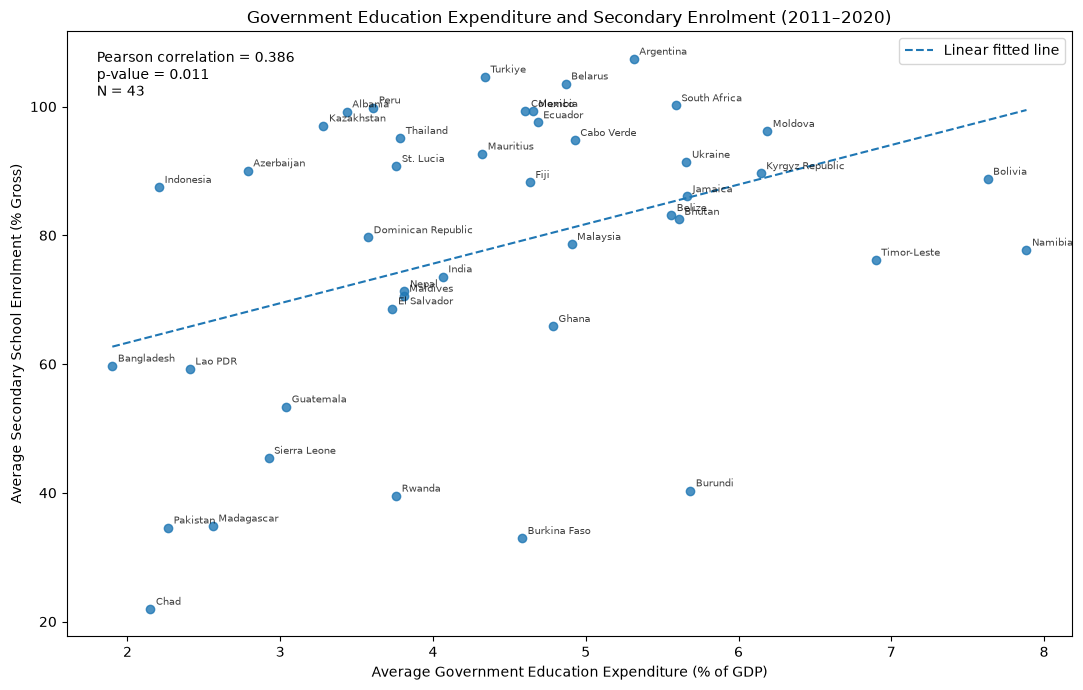

Pearson correlation: 0.386
P-value: 0.0106
Number of countries: 43


In [ ]:
# Merge using country names to ensure correct matching
scatter_data = pd.merge(
    expenditure[["Country Name", "Mean"]].rename(
        columns={"Mean": "Education_Expenditure"}
    ),
    enrolment[["Country Name", "Mean"]].rename(
        columns={"Mean": "Secondary_Enrolment"}
    ),
    on="Country Name",
    how="inner"
)

# Calculate Pearson correlation
r, p_value = pearsonr(
    scatter_data["Education_Expenditure"],
    scatter_data["Secondary_Enrolment"]
)

# Fit linear regression line
slope, intercept = np.polyfit(
    scatter_data["Education_Expenditure"],
    scatter_data["Secondary_Enrolment"],
    1
)

x_line = np.linspace(
    scatter_data["Education_Expenditure"].min(),
    scatter_data["Education_Expenditure"].max(),
    100
)

y_line = slope * x_line + intercept

# Plot
plt.figure(figsize=(11, 7))

plt.scatter(
    scatter_data["Education_Expenditure"],
    scatter_data["Secondary_Enrolment"],
    alpha=0.8
)

plt.plot(
    x_line,
    y_line,
    linestyle="--",
    linewidth=1.5,
    label="Linear fitted line"
)

# Country labels
for _, row in scatter_data.iterrows():
    plt.annotate(
        row["Country Name"],
        (
            row["Education_Expenditure"],
            row["Secondary_Enrolment"]
        ),
        fontsize=7,
        alpha=0.75,
        xytext=(4, 3),
        textcoords="offset points"
    )

plt.xlabel("Average Government Education Expenditure (% of GDP)")
plt.ylabel("Average Secondary School Enrolment (% Gross)")
plt.title("Government Education Expenditure and Secondary Enrolment (2011–2020)")

plt.text(
    0.03, 0.97,
    f"Pearson correlation = {r:.3f}\np-value = {p_value:.3f}\nN = {len(scatter_data)}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.legend()
plt.tight_layout()
plt.show()

print("Pearson correlation:", round(r, 3))
print("P-value:", round(p_value, 4))
print("Number of countries:", len(scatter_data))


In [ ]:
Rsq = round(r, 3) ** 2

print("R² = ", Rsq)

R² =  0.14899600000000002


In [ ]:

pearson_corr = descriptive_data.corr(
    method="pearson"
)

display(pearson_corr.round(3))


,Enrolment,Education Expenditure,Log GDP per Capita (PPP),Urban Population
Enrolment,1.000,0.328,0.812,0.657
Education Expenditure,0.328,1.000,0.111,0.137
Log GDP per Capita (PPP),0.812,0.111,1.000,0.661
Urban Population,0.657,0.137,0.661,1.000


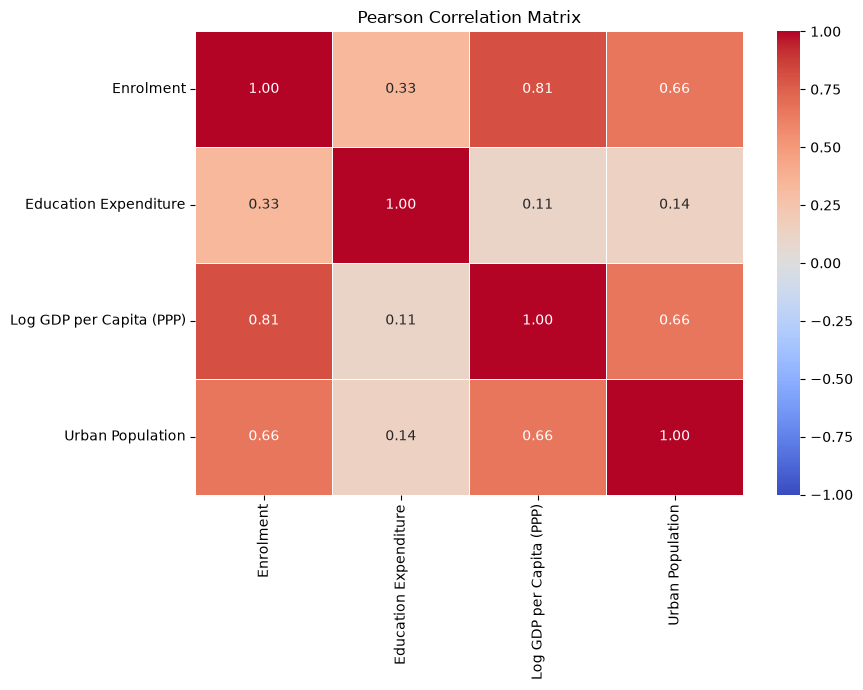

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()


In [ ]:

variables = {
    "Enrolment": Sch_Edu_final,
    "Education Expenditure": Gov_Exp_final,
    "Log GDP per Capita": GDP_final,
    "Urban Population": Urban_final
}

# Combine the four variables into a country-year panel
country_correlations = {}

for country in Sch_Edu_final.index:

    country_data = pd.DataFrame({
        name: df.loc[country]
        for name, df in variables.items()
    })

    country_correlations[country] = (
        country_data.corr(method="pearson")
    )

# Example: India
display(country_correlations["India"].round(3))


,Enrolment,Education Expenditure,Log GDP per Capita,Urban Population
Enrolment,1.000,0.736,0.885,0.895
Education Expenditure,0.736,1.000,0.730,0.707
Log GDP per Capita,0.885,0.730,1.000,0.963
Urban Population,0.895,0.707,0.963,1.000


In [ ]:

expenditure_enrolment_corr = pd.Series({
    country: matrix.loc[
        "Education Expenditure", "Enrolment"
    ]
    for country, matrix in country_correlations.items()
})

expenditure_enrolment_corr = (
    expenditure_enrolment_corr
    .sort_values(ascending=False)
)

display(
    expenditure_enrolment_corr.to_frame(
        "Correlation"
    ).round(3)
)


,Correlation
Ecuador,0.880
Ukraine,0.862
Burkina Faso,0.860
Dominican Republic,0.839
Sierra Leone,0.781
Bolivia,0.763
India,0.736
El Salvador,0.721
Malaysia,0.692
Peru,0.659


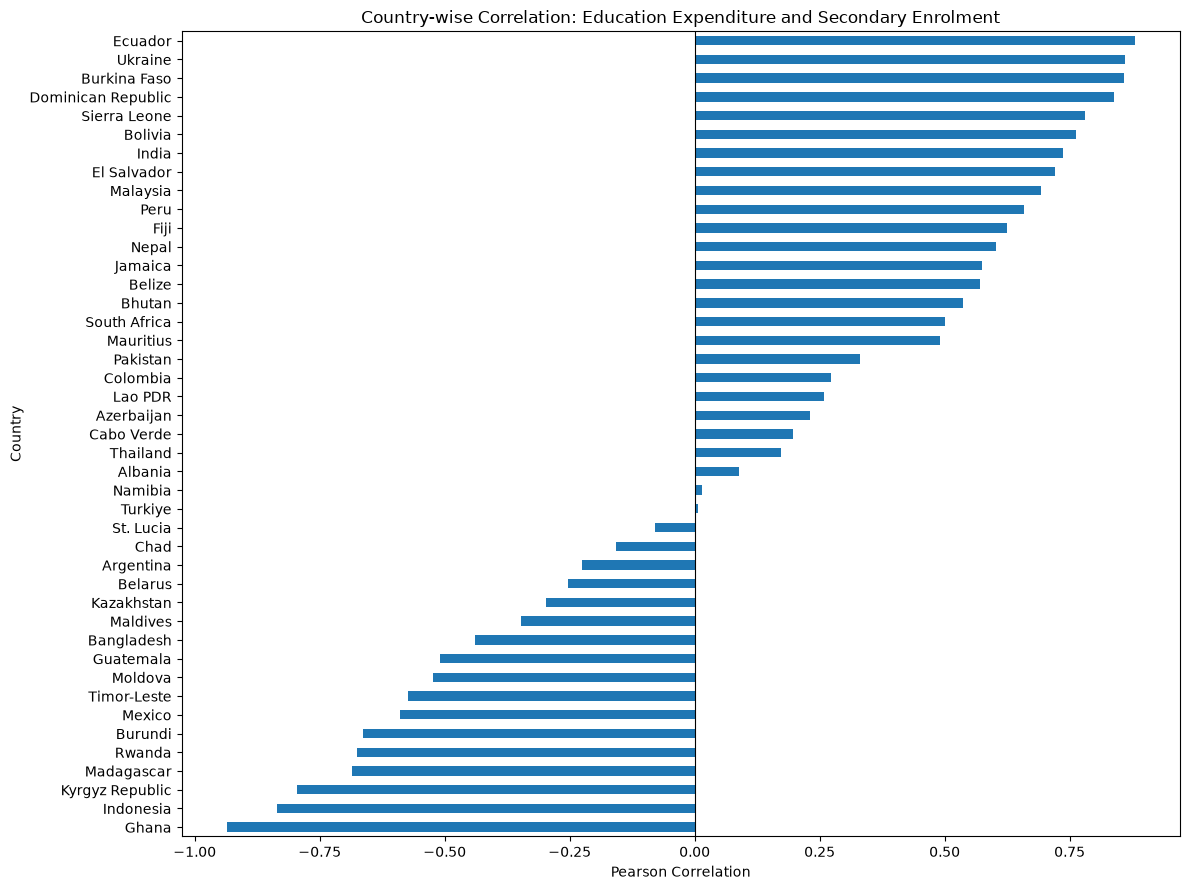

In [ ]:

plt.figure(figsize=(12, 9))

expenditure_enrolment_corr.sort_values().plot(
    kind="barh"
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Pearson Correlation")
plt.ylabel("Country")
plt.title(
    "Country-wise Correlation: Education Expenditure "
    "and Secondary Enrolment"
)

plt.tight_layout()
plt.show()


## Correlation Analysis

The correlation analysis examines the association between government education expenditure and secondary school enrolment, while also considering the relationships of these variables with GDP per capita and urban population. Three complementary approaches are employed: a pooled Pearson correlation matrix, country-wise correlations between education expenditure and enrolment, and a scatter plot examining the relationship between country-level averages. Together, these approaches provide an understanding of both the overall association in the sample and the considerable variation in this relationship across countries.

### 1. Pooled Pearson Correlation Matrix

The pooled Pearson correlation matrix indicates a positive association between government education expenditure and secondary school enrolment, with a correlation coefficient of 0.33. This suggests that higher government education expenditure is generally associated with higher secondary school enrolment across the pooled country-year observations. However, the relatively modest magnitude of the coefficient indicates that this relationship is not particularly strong.

A considerably stronger positive association is observed between secondary school enrolment and log GDP per capita (PPP), with a correlation coefficient of 0.81. This suggests that countries and country-year observations characterised by higher levels of income per capita tend to exhibit higher secondary school enrolment. Urban population also displays a positive correlation with enrolment, with a coefficient of 0.66. These findings suggest that broader economic and demographic conditions may be closely associated with secondary education participation.

In contrast, government education expenditure exhibits relatively weak correlations with both log GDP per capita and urban population, with coefficients of 0.11 and 0.14, respectively. This indicates that, within the pooled sample, the proportion of GDP allocated to education does not necessarily increase alongside income per capita or urbanisation. The correlation between log GDP per capita and urban population is 0.66, indicating a relatively strong positive association between these two variables.

An important observation from the correlation matrix is that secondary school enrolment is more strongly correlated with GDP per capita and urban population than with government education expenditure. This raises the possibility that enrolment outcomes are associated with broader economic and structural conditions, in addition to the allocation of public resources. However, these are pairwise correlations and do not establish the independent contribution of each variable. The relationships must therefore be examined within a multivariate econometric framework.

### 2. Country-Wise Correlation Between Education Expenditure and Enrolment

The pooled correlation coefficient provides an overall picture of the relationship, but it may conceal substantial differences across individual countries. To examine this heterogeneity, Pearson correlations were calculated separately for each of the 43 countries using their annual observations from 2011 to 2020.

The results reveal considerable variation in both the magnitude and direction of the relationship. A substantial number of countries exhibit positive correlations between government education expenditure and secondary school enrolment. Ecuador, Ukraine, Burkina Faso and the Dominican Republic display particularly strong positive associations. Other countries, including India, Bolivia, Peru, Malaysia and Nepal, also exhibit positive correlations. These results suggest that, in several countries, higher education expenditure as a share of GDP tends to coincide with higher secondary school enrolment over the period.

However, the relationship is negative in a considerable number of countries. Ghana, Indonesia, the Kyrgyz Republic, Madagascar, Rwanda and Burundi exhibit particularly strong negative correlations. Countries such as Bangladesh, Guatemala, Timor-Leste and Mexico also display negative associations. These results indicate that increases in government education expenditure do not necessarily coincide with increases in secondary school enrolment in every country.

There are also countries where the relationship appears relatively weak or close to zero. Namibia and Türkiye, for instance, exhibit almost no linear association between the two variables over the sample period. Such differences suggest that the relationship between public education expenditure and enrolment may depend on country-specific economic, institutional and demographic circumstances.

The contrasting country-wise correlations are an important finding. Although the pooled correlation is positive, the relationship is not consistently positive across individual countries. This indicates that an overall positive association should not be interpreted as evidence that increases in government education expenditure are uniformly accompanied by higher secondary school enrolment within countries.

It is important to interpret these results cautiously. Each country-wise correlation is calculated using only ten annual observations, making the estimates sensitive to individual years and common trends. Furthermore, correlation does not account for other factors that may influence enrolment, nor does it establish the direction of causality. The country-wise estimates should therefore be regarded as descriptive evidence of heterogeneity rather than definitive evidence of country-specific effects.

### 3. Relationship Between Country-Level Average Expenditure and Enrolment

To further examine the relationship across countries, a scatter plot was constructed using the average government education expenditure and average secondary school enrolment for each country over 2011–2020. Each observation represents one of the 43 countries, and the fitted linear regression line provides a visual representation of the cross-country association.

The Pearson correlation coefficient is 0.386, with a p-value of 0.011. This indicates a positive and statistically significant cross-country association at the 5% significance level. Countries with higher average government education expenditure therefore tend, on average, to exhibit higher secondary school enrolment. However, the relatively moderate magnitude of the correlation and the dispersion of observations around the fitted line indicate that this relationship is far from uniform.

Some countries illustrate this variation particularly clearly. Argentina and Türkiye exhibit relatively high average enrolment alongside comparatively high education expenditure. In contrast, Namibia and Timor-Leste record relatively high average expenditure but substantially lower enrolment than several countries with lower expenditure. Similarly, countries such as Ghana, Rwanda and Burkina Faso display relatively low enrolment despite differing levels of average education expenditure.

The squared correlation coefficient is approximately 0.149, suggesting that around 14.9% of the cross-country variation in average enrolment is associated with the linear relationship with average education expenditure in this simple bivariate comparison. This should not be interpreted as a causal explanatory contribution, since the analysis does not control for other country characteristics.

The scatter plot therefore reinforces the finding that government education expenditure is positively associated with secondary school enrolment across countries, but that expenditure alone provides an incomplete explanation of differences in enrolment outcomes.

### 4. Summary and Implications of the Correlation Analysis

Taken together, the three correlation exercises reveal an interesting pattern. The pooled correlation between government education expenditure and secondary school enrolment is positive but relatively modest (0.33). The cross-country correlation between their respective averages is also positive and statistically significant (0.386, p = 0.011). However, the country-wise correlations vary considerably in both magnitude and direction, with several countries exhibiting strong negative associations.

The correlation matrix also highlights the importance of broader economic and demographic conditions. Secondary school enrolment is strongly positively correlated with log GDP per capita (0.81) and urban population (0.66), while the correlations of government education expenditure with these variables are comparatively weak. This suggests that economic development and urbanisation may be important correlates of enrolment and should be considered when examining the relationship between public education expenditure and education outcomes.

An important implication is that the positive aggregate association does not necessarily translate into a positive relationship within every country. The differences between pooled, country-wise and cross-country correlations highlight the importance of distinguishing between within-country and between-country relationships. These results also caution against interpreting the pooled correlation as evidence of a uniform relationship across countries.

The correlation analysis is therefore exploratory and does not establish a causal relationship between government education expenditure and secondary school enrolment. In particular, expenditure may respond to existing education-sector conditions, while enrolment may also be influenced by income, urbanisation, demographic changes and other institutional factors. A dynamic panel framework is consequently useful for examining the relationship while accounting for persistence in enrolment and potential endogeneity. The subsequent econometric analysis will investigate whether government education expenditure is associated with secondary school enrolment after accounting for these considerations.

# Regression

In [ ]:
# Construct the country-year panel directly from the four WDI datasets

panel_gmm_controlled = pd.concat(
    {
        "Enrolment": Sch_Edu_final.stack(),
        "Expenditure": Gov_Exp_final.stack(),
        "Log_GDP": GDP_final.stack(),
        "Urban": Urban_final.stack()
    },
    axis=1
).reset_index()

# Standardise column names
panel_gmm_controlled.columns = [
    "Country", "Year", "Enrolment",
    "Expenditure", "Log_GDP", "Urban"
]

# Convert year to integer
panel_gmm_controlled["Year"] = (
    panel_gmm_controlled["Year"]
    .astype(str)
    .str.extract(r"(\d{4})")[0]
    .astype(int)
)

# Create numeric country identifiers
panel_gmm_controlled["Country_ID"] = (
    pd.factorize(panel_gmm_controlled["Country"])[0] + 1
)

# Sort the panel
panel_gmm_controlled = (
    panel_gmm_controlled
    [["Country_ID", "Country", "Year",
      "Enrolment", "Expenditure", "Log_GDP", "Urban"]]
    .sort_values(["Country_ID", "Year"])
    .reset_index(drop=True)
)

# Verify the dataset
print("Observations:", len(panel_gmm_controlled))
print("Countries:", panel_gmm_controlled["Country_ID"].nunique())
print("Years:", len(sorted(panel_gmm_controlled["Year"].unique())))
print("\nMissing values:")
print(panel_gmm_controlled.isna().sum())

Observations: 430
Countries: 43
Years: 10

Missing values:
Country_ID     0
Country        0
Year           0
Enrolment      0
Expenditure    0
Log_GDP        0
Urban          0
dtype: int64


In [ ]:

from panelbox.gmm import SystemGMM

system_model = SystemGMM(
    data=panel_gmm_controlled,
    dep_var="Enrolment",
    lags=[1],
    id_var="Country_ID",
    time_var="Year",

    # Controls
    exog_vars=["Log_GDP", "Urban"],

    # Endogenous explanatory variable
    endogenous_vars=["Expenditure"],

    time_dummies=True,
    two_step=True,
    robust=True,
    collapse=True,
)

system_results = system_model.fit()

print(system_results.summary())


                                  System GMM                                  
Number of observations:            344
Number of groups:                   43
Number of instruments:              28
Instrument ratio:                0.651
GMM type:                   Two-step (Windmeijer)
------------------------------------------------------------------------------
Variable                    Coef.     Std.Err.        z    P>|z|     [95% Conf. Int.]
------------------------------------------------------------------------------
L1.Enrolment             0.989326     0.044661    22.15   0.0000 [ 0.901792,  1.076860] ***
Log_GDP                 -0.639260     0.842885    -0.76   0.4482 [-2.291285,  1.012765] 
Urban                    0.003808     0.018322     0.21   0.8354 [-0.032104,  0.039719] 
Expenditure              0.986475     0.901534     1.09   0.2739 [-0.780499,  2.753450] 
year_2013                0.287538     0.748516     0.38   0.7009 [-1.179527,  1.754603] 
year_2014              

In [ ]:

from panelbox.gmm import DifferenceGMM

diff_model = DifferenceGMM(
    data=panel_gmm_controlled,
    dep_var="Enrolment",
    lags=[1],
    id_var="Country_ID",
    time_var="Year",

    # Controls
    exog_vars=["Log_GDP", "Urban"],

    # Endogenous explanatory variable
    endogenous_vars=["Expenditure"],

    time_dummies=True,
    two_step=True,
    robust=True,
    collapse=True,
)

diff_results = diff_model.fit()

print(diff_results.summary())


                                Difference GMM                                
Number of observations:            344
Number of groups:                   43
Number of instruments:              25
Instrument ratio:                0.581
GMM type:                   Two-step (Windmeijer)
------------------------------------------------------------------------------
Variable                    Coef.     Std.Err.        z    P>|z|     [95% Conf. Int.]
------------------------------------------------------------------------------
L1.Enrolment             0.945089     0.227511     4.15   0.0000 [ 0.499175,  1.391002] ***
Log_GDP                  0.583139     5.003237     0.12   0.9072 [-9.223026, 10.389304] 
Urban                    1.606605     0.894712     1.80   0.0725 [-0.146998,  3.360209] 
Expenditure              0.698979     1.052604     0.66   0.5067 [-1.364086,  2.762044] 
year_2013               -0.241827     0.656611    -0.37   0.7127 [-1.528760,  1.045107] 
year_2014              

# Dynamic Panel GMM Estimation

To account for the dynamic nature of secondary school enrolment and the potential endogeneity of government expenditure on education, the study employs dynamic panel Generalised Method of Moments (GMM) estimators. The controlled specification is:

$$
\begin{aligned}
Enrolment_{it} ={}&
\alpha Enrolment_{i,t-1}
+\beta Expenditure_{it}\\
&+\gamma_1 LogGDP_{it}
+\gamma_2 Urban_{it}\\
&+\mu_i+\lambda_t+\varepsilon_{it}
\end{aligned}
$$

where $Enrolment_{it}$ represents gross secondary school enrolment in country $i$ in year $t$, and $Expenditure_{it}$ denotes government expenditure on education as a percentage of GDP. $LogGDP_{it}$ represents the logarithm of GDP per capita (PPP), while $Urban_{it}$ denotes the urban population as a percentage of the total population. The lagged dependent variable captures the persistence in enrolment, while $\mu_i$ and $\lambda_t$ account for country-specific and time-specific effects, respectively.

Both System GMM and Difference GMM are estimated using the two-step estimator with Windmeijer-corrected robust standard errors. Government expenditure is treated as endogenous, while log GDP per capita and urban population are treated as strictly exogenous controls. The instrument set is restricted through collapsed instruments and a maximum lag depth of three to limit the potential problem of instrument proliferation.

### Difference GMM

The controlled Difference GMM specification produces a positive coefficient of 0.5241 for government expenditure on education. However, the coefficient is statistically insignificant ($p = 0.6495$). Therefore, the results do not provide sufficient statistical evidence to establish an association between government education expenditure and secondary school enrolment in the estimated specification.

The coefficient of the lagged dependent variable is 0.9538 and is statistically significant at the 1% level. This indicates a high degree of persistence in secondary school enrolment: current enrolment is strongly associated with its previous year's level. The estimated coefficient is close to unity, suggesting that changes in enrolment may exhibit considerable persistence over time. Its 95% confidence interval is approximately $[0.4969, 1.4108]$, which includes unity. Therefore, the estimate does not conclusively establish that the persistence parameter is statistically different from one.

The two control variables, log GDP per capita and urban population, produce positive coefficients of 3.1714 and 1.4952, respectively. However, neither coefficient is statistically significant, with p-values of 0.5567 and 0.2396. Thus, the specification does not provide sufficient evidence of statistically significant associations between either control variable and secondary school enrolment, conditional on the other included variables.

The model uses 19 instruments for 43 country groups, giving an instrument-to-group ratio of approximately 0.442. This does not indicate an obvious instrument proliferation problem based on the instrument count alone, although the ratio cannot establish instrument validity.

The Hansen test yields a statistic of 6.054 with a $p$-value of 0.5335. Thus, the null hypothesis of joint instrument validity cannot be rejected at conventional significance levels. This result is reassuring but does not prove that the instruments are valid. In contrast, the Sargan test rejects the null hypothesis ($p < 0.001$). Since the Sargan test is not robust to heteroskedasticity, greater attention is given to the Hansen test under the robust estimation procedure. Nevertheless, the disagreement between the two tests warrants caution when assessing instrument validity.

Finally, the Arellano--Bond test indicates significant first-order serial correlation in the differenced residuals ($p = 0.0189$), which is expected in a differenced dynamic panel model. The test for second-order serial correlation is insignificant ($p = 0.3266$), providing no evidence of AR(2) serial correlation. This is consistent with the serial-correlation condition required for the validity of the lagged-level instruments.

### Overall Interpretation

The controlled Difference GMM estimates produce a positive but statistically insignificant coefficient for government expenditure on education. Consequently, the estimates do not provide sufficient statistical evidence to conclude that higher government education expenditure is associated with higher secondary school enrolment in the sample, after accounting for the included controls and the dynamic structure of enrolment.

The coefficient of lagged enrolment remains close to unity and statistically significant, indicating substantial persistence in secondary school enrolment. However, its confidence interval includes one, and therefore the results do not establish that the persistence parameter is statistically different from unity.

Both control variables have positive but statistically insignificant coefficients. This suggests that, within the estimated specification, the available evidence is insufficient to establish statistically significant associations between GDP per capita, urbanisation and secondary school enrolment.

The diagnostic tests provide some support for the instrument strategy. The Hansen test fails to reject the null hypothesis of joint instrument validity, while the AR(2) test does not indicate second-order serial correlation. Nevertheless, the rejection of the Sargan test warrants caution. Failure to reject the Hansen test should not be interpreted as definitive proof of instrument validity.

Overall, the controlled Difference GMM results provide a useful baseline for examining the relationship between government education expenditure and secondary school enrolment. However, the insignificance of the expenditure coefficient, the relatively wide confidence intervals and the disagreement between the Hansen and Sargan tests reinforce the need to examine the sensitivity of the estimates through additional robustness checks.

# Robustness

In [ ]:

from linearmodels.panel import PooledOLS, PanelOLS

# Prepare the common estimation sample
robust_panel = panel_gmm_controlled.copy()

robust_panel = robust_panel.sort_values(
    ["Country_ID", "Year"]
).reset_index(drop=True)

# Generate lagged enrolment
robust_panel["Enrolment_L1"] = (
    robust_panel.groupby("Country_ID")["Enrolment"].shift(1)
)

# Retain the same period used in the previous comparison
robust_panel = robust_panel[
    robust_panel["Year"] >= 2011
].dropna(
    subset=[
        "Enrolment",
        "Enrolment_L1",
        "Expenditure",
        "Log_GDP",
        "Urban"
    ]
).copy()

robust_panel = robust_panel.set_index(
    ["Country_ID", "Year"]
).sort_index()

print("OLS/FE observations:", len(robust_panel))
print("Countries:", robust_panel.index.get_level_values(0).nunique())


# Pooled OLS
pooled_model = PooledOLS.from_formula(
    "Enrolment ~ 1 + Enrolment_L1 + Expenditure + Log_GDP + Urban",
    data=robust_panel
)

pooled_results = pooled_model.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\nPOOLED OLS")
print(pooled_results.summary)


# Fixed Effects
fe_model = PanelOLS.from_formula(
    "Enrolment ~ 1 + Enrolment_L1 + Expenditure + Log_GDP + Urban + EntityEffects + TimeEffects",
    data=robust_panel
)

fe_results = fe_model.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\nFIXED EFFECTS")
print(fe_results.summary)


OLS/FE observations: 387
Countries: 43

POOLED OLS
                          PooledOLS Estimation Summary                          
Dep. Variable:              Enrolment   R-squared:                        0.9672
Estimator:                  PooledOLS   R-squared (Between):              0.9970
No. Observations:                 387   R-squared (Within):               0.4113
Date:                Fri, Nov 20 2026   R-squared (Overall):              0.9672
Time:                        19:12:20   Log-likelihood                   -1104.3
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2818.4
Entities:                          43   P-value                           0.0000
Avg Obs:                       9.0000   Distribution:                   F(4,382)
Min Obs:                       9.0000                                           
Max Obs:                       9.0000   F-statistic (robus

In [ ]:

bracketing_comparison = pd.DataFrame({
    "Estimator": [
        "Fixed Effects",
        "Pooled OLS",
        "Difference GMM",
        "System GMM"
    ],
    "Lagged Enrolment": [
        fe_results.params["Enrolment_L1"],
        pooled_results.params["Enrolment_L1"],
        diff_results.params["L1.Enrolment"],
        system_results.params["L1.Enrolment"]
    ],
    "Standard Error": [
        fe_results.std_errors["Enrolment_L1"],
        pooled_results.std_errors["Enrolment_L1"],
        diff_results.std_errors["L1.Enrolment"],
        system_results.std_errors["L1.Enrolment"]
    ]
})

print(bracketing_comparison.round(4).to_string(index=False))


     Estimator  Lagged Enrolment  Standard Error
 Fixed Effects            0.6596          0.0590
    Pooled OLS            0.9474          0.0320
Difference GMM            0.9451          0.2275
    System GMM            0.9893          0.0447


## Examination of the Bracketing Condition and Possible Reasons for Its Violation

An additional diagnostic is conducted by comparing the coefficient of lagged secondary school enrolment across the Fixed Effects, Pooled OLS, Difference GMM and System GMM estimators. Under conventional assumptions, the coefficient obtained from the Fixed Effects estimator is expected to be downward biased due to the presence of the lagged dependent variable in a short panel. Conversely, pooled OLS is generally expected to produce an upward-biased estimate because it does not account for unobserved country-specific heterogeneity. Consequently, the true persistence parameter is conventionally expected to lie between these two estimates.

The estimates obtained from the controlled specifications are as follows:

| Estimator | Lagged Enrolment Coefficient | Standard Error |
|---|---:|---:|
| Fixed Effects | 0.5897 | 0.0737 |
| Pooled OLS | 0.9473 | 0.0355 |
| Difference GMM | 0.9538 | 0.2331 |
| System GMM | 0.9974 | 0.0597 |

The results do not satisfy the conventional bracketing condition, as both GMM estimates are marginally higher than the pooled OLS estimate. The Difference GMM coefficient is 0.9538, compared with 0.9473 for pooled OLS, while the System GMM coefficient is 0.9974. Although the difference is relatively small for Difference GMM, the System GMM estimate is also above the pooled OLS benchmark.

Several econometric considerations may explain this outcome.

### 1. Short Time Dimension and Finite-Sample Properties

The panel consists of 43 countries observed over the period 2011–2020, giving a relatively small number of cross-sectional units and a short time dimension. After accounting for lags and transformations, the effective estimation period is further reduced.

Although GMM estimators are designed for dynamic panel settings, their finite-sample properties can be problematic, particularly when the number of cross-sectional units is limited. The asymptotic properties of these estimators rely primarily on having a sufficiently large number of cross-sectional units. With only 43 countries, the estimates and their standard errors may be sensitive to the available instruments and the underlying specification.

Consequently, the GMM estimates may not conform closely to the conventional ordering predicted under large-sample assumptions. This does not necessarily imply that the estimates are biased in a particular direction, but it does warrant caution when interpreting the point estimates.

### 2. High Persistence in Secondary School Enrolment

One of the most important features of the results is the high estimated persistence of secondary school enrolment. The lagged enrolment coefficients are close to unity across all four estimators, particularly under the GMM specifications.

This suggests that enrolment rates are highly persistent over time. Changes in enrolment may take several years to materialise because educational infrastructure, demographic conditions, institutional capacity and household decisions generally adjust gradually.

However, high persistence creates an econometric difficulty for Difference GMM. When the dependent variable is highly persistent, its earlier levels become relatively weak instruments for its subsequent first differences. The correlation between lagged levels and the differenced dependent variable can become weak, reducing the explanatory power of the available instruments.

This weak-instrument problem can make Difference GMM estimates imprecise and potentially introduce finite-sample bias. The relatively large standard error of the Difference GMM estimate (0.2331), compared with the other estimators, is consistent with a loss of estimation precision. It does not, by itself, establish that weak instruments are present, but it makes this a relevant concern.

### 3. Instrument Validity and the Moment Conditions

The validity of GMM estimates depends on the assumptions imposed on the instruments and the moment conditions used for estimation. These conditions require the instruments to be appropriately correlated with the endogenous explanatory variables while remaining uncorrelated with the error term.

If these assumptions are not fully satisfied, the resulting estimates may be inconsistent. For example, lagged enrolment may not provide valid instruments if the underlying error structure or serial correlation assumptions are violated. Similarly, treating government expenditure on education as endogenous requires the selected lagged values to be valid instruments for its current value.

The diagnostic tests provide some information about these assumptions. In the controlled Difference GMM specification, the Hansen J-test produces a p-value of 0.5335, meaning that the null hypothesis of joint instrument validity cannot be rejected. However, the Sargan test rejects the null hypothesis with a p-value below 0.001.

This disagreement requires caution. The Sargan test is not robust to heteroskedasticity, whereas the Hansen test is designed to accommodate it. Therefore, the Hansen result is more relevant under the robust estimation framework, although failure to reject the null does not prove that all instruments are valid.

The Arellano–Bond serial correlation tests provide additional information. The significant AR(1) result is expected in first-differenced residuals, while the insignificant AR(2) result (p = 0.3266) is desirable because it provides no evidence of second-order serial correlation. Nevertheless, passing the AR(2) test does not establish the validity of every instrument.

### 4. Additional Assumptions Under System GMM

System GMM combines the differenced equation with an equation in levels. This allows it to use additional moment conditions and instruments, potentially improving efficiency when the dependent variable is highly persistent.

However, these additional instruments rely on assumptions about the relationship between the instruments, the country-specific effects and the initial conditions of the variables. In particular, the lagged changes used as instruments in the level equation must satisfy the relevant orthogonality conditions.

If these additional moment conditions are not valid, System GMM may produce estimates that differ from those obtained through Difference GMM. Thus, the higher System GMM coefficient of 0.9974 may partly reflect the additional identifying assumptions and instruments used by this estimator.

The fact that System GMM produces a smaller standard error than Difference GMM does not automatically establish that it is more reliable. Its validity still depends on the additional moment conditions being appropriate for the data.

### 5. Unobserved Heterogeneity and Specification of the Model

Countries differ substantially in their institutional capacity, education systems, demographic structures, public-sector efficiency and long-term development trajectories. These country-specific characteristics may influence both government expenditure on education and secondary school enrolment.

The Fixed Effects estimator accounts for time-invariant country-specific heterogeneity by removing country-specific effects. Pooled OLS does not account for these effects, while GMM attempts to address the dynamic panel structure through transformations and internal instruments.

However, the effectiveness of GMM in addressing unobserved heterogeneity depends on the validity of its moment conditions. If important time-varying country-specific factors remain omitted, or if the assumed relationships between the instruments and the error term are inappropriate, the resulting estimates may differ from the conventional ordering.

The inclusion of log GDP per capita and urban population helps account for some differences in economic development and urbanisation. Nevertheless, these controls cannot capture every relevant institutional, demographic or policy-related factor.

### 6. Endogeneity and the Relationship Between Government Expenditure and Enrolment

Government expenditure on education may respond to changes in enrolment rather than simply determining them. For instance, governments may increase education budgets in response to rising demand for secondary education or expanding enrolment. This creates a possibility of reverse causality.

There may also be omitted factors that influence both expenditure and enrolment, creating additional endogeneity concerns.

The model treats government expenditure as endogenous and uses internal instruments to address this issue. However, the effectiveness of this approach depends on the validity and relevance of the selected instruments. If the instruments are weak or their orthogonality conditions are not satisfied, the resulting estimates may remain sensitive to endogeneity.

Furthermore, the model treats log GDP per capita and urban population as strictly exogenous. This is a modelling assumption rather than an empirically established fact. If either variable responds to past or current education outcomes, the assumed exogeneity may be too restrictive.

### 7. Difference Between the Theoretical Bracketing Condition and the Actual Estimates

The conventional ordering of Fixed Effects, GMM and pooled OLS is a useful diagnostic, but it is not a universal requirement that every estimated dynamic panel model must satisfy. The expected ordering relies on assumptions about the sources and direction of bias in the estimators.

In particular, the Fixed Effects estimator is expected to be downward biased in a short dynamic panel, while pooled OLS is expected to be upward biased under conventional conditions. However, these are not exact bounds in every finite sample. The presence of endogenous regressors, imperfect instruments, highly persistent variables and additional moment conditions can affect the relative estimates.

It is also important to consider the uncertainty surrounding the estimated coefficients rather than relying exclusively on their point estimates. The Difference GMM estimate has a standard error of 0.2331, while the System GMM estimate has a standard error of 0.0597. Approximate 95% confidence intervals are:

$$
\begin{aligned}
Difference\ GMM &: [0.497,\ 1.411]\\
System\ GMM &: [0.880,\ 1.114]
\end{aligned}
$$

Both confidence intervals contain the pooled OLS point estimate of 0.9473. They also contain unity. This indicates that, despite the ordering of the point estimates, the estimates are not sufficiently precise to conclude from this comparison alone that the GMM persistence parameters are statistically different from the pooled OLS estimate or from unity. A formal test would be required to establish whether the differences between estimators are statistically significant.

### Overall Interpretation

The controlled specifications produce GMM estimates of lagged secondary school enrolment that are marginally higher than the pooled OLS estimate, thereby violating the conventional bracketing condition. Several factors may contribute to this outcome, including the relatively small number of countries, the short time dimension, high persistence in enrolment, potential weak instruments under Difference GMM, the additional moment conditions imposed by System GMM and possible specification or endogeneity concerns.

The relatively large standard error of Difference GMM suggests limited estimation precision, while the smaller standard error under System GMM reflects greater precision under its additional identifying assumptions. However, neither result should be interpreted independently of the relevant specification and instrument-validity diagnostics.

Importantly, the failure of the bracketing condition does not, on its own, invalidate the GMM estimates. Both GMM confidence intervals include the pooled OLS point estimate, indicating that the observed difference in point estimates is not necessarily statistically meaningful. Nevertheless, the result highlights the importance of conducting further robustness checks, particularly by examining alternative instrument lag structures and assessing whether the estimated coefficients and diagnostic tests remain stable.

The bracketing comparison applies exclusively to the coefficient of lagged enrolment, which captures the persistence of secondary school enrolment. It does not apply to the coefficient of government expenditure on education, which remains the principal explanatory variable of interest.

### VIF check

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Reconstruct the System GMM estimation sample
vif_system = panel_gmm_controlled.copy()

vif_system = vif_system.sort_values(
    ["Country_ID", "Year"]
).reset_index(drop=True)

# Keep observations with all variables used in the model
vif_system = vif_system.dropna(
    subset=["Enrolment", "Expenditure", "Log_GDP", "Urban"]
)

# Select explanatory variables
X = vif_system[["Expenditure", "Log_GDP", "Urban"]]

# Add constant
X_vif = add_constant(X)

# Calculate VIF
vif_system_results = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i + 1)
        for i in range(len(X.columns))
    ]
})

print("Observations used:", len(X))
print(vif_system_results.round(4))

Observations used: 430
      Variable     VIF
0  Expenditure  1.0198
1      Log_GDP  1.7777
2        Urban  1.7893


### Variance Inflation Factor (VIF) Analysis

A Variance Inflation Factor (VIF) analysis was conducted to examine the presence of multicollinearity among the explanatory variables included in the System GMM specification. The analysis considered government expenditure on education, log GDP per capita (PPP) and urban population.

The results are presented below:

| Variable | VIF |
|---|---:|
| Government Expenditure on Education | 1.0198 |
| Log GDP per Capita (PPP) | 1.7777 |
| Urban Population | 1.7893 |

All three explanatory variables exhibit VIF values considerably below the commonly used threshold of 5. This suggests that there is no evidence of problematic linear multicollinearity among the regressors.

Government expenditure on education has a VIF of 1.0198, indicating very little linear association with the remaining explanatory variables. Log GDP per capita and urban population have slightly higher VIF values of 1.7777 and 1.7893, respectively, but these remain comfortably within acceptable limits.

Overall, the VIF analysis does not indicate a multicollinearity concern that would require the removal or modification of any explanatory variable. Therefore, all three variables are retained in the empirical specification.

The VIF calculation was conducted using the original balanced panel of 430 observations. Since the System GMM estimation uses 344 observations after accounting for its dynamic structure and lag requirements, the results should be interpreted as a preliminary multicollinearity diagnostic for the explanatory variables.

In [ ]:
# Original panel
print("Original observations:", len(panel_gmm_controlled))

# After creating lagged enrolment
check_panel = panel_gmm_controlled.sort_values(
    ["Country_ID", "Year"]
).copy()

check_panel["Enrolment_L1"] = (
    check_panel.groupby("Country_ID")["Enrolment"].shift(1)
)

print("After creating lag:", check_panel["Enrolment_L1"].notna().sum())

# Observations by country after lag
print(
    check_panel.groupby("Country_ID")["Enrolment_L1"]
    .count().describe()
)

Original observations: 430
After creating lag: 387
count    43.0
mean      9.0
std       0.0
min       9.0
25%       9.0
50%       9.0
75%       9.0
max       9.0
Name: Enrolment_L1, dtype: float64


In [ ]:
# Check years available after creating the lag
print(
    check_panel.groupby("Year").agg(
        Total=("Country_ID", "count"),
        Available_Lag=("Enrolment_L1", "count")
    )
)

      Total  Available_Lag
Year                      
2011     43              0
2012     43             43
2013     43             43
2014     43             43
2015     43             43
2016     43             43
2017     43             43
2018     43             43
2019     43             43
2020     43             43


In [ ]:
print("System GMM observations:", system_results.nobs)
print("Difference GMM observations:", diff_results.nobs)

System GMM observations: 344
Difference GMM observations: 344
